In [1]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
serenaraju_yawn_eye_dataset_new_path = kagglehub.dataset_download('serenaraju/yawn-eye-dataset-new')
arafatsahinafridi_multi_class_driver_behavior_image_dataset_path = kagglehub.dataset_download('arafatsahinafridi/multi-class-driver-behavior-image-dataset')

print('Data source import complete.')

Data source import complete.


In [2]:
# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Basic utilities
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from glob import glob
import random
from PIL import Image
import plotly.express as px

# Deep learning: TensorFlow and Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization)
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Metrics and Evaluation
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

2026-11-01 02:31:36.649109: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793500296.822339      40 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793500296.881168      40 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


# **Dataset Exploration Code for Yawn-Eye Dataset**

In [3]:
# Define base path
base_path = "/kaggle/input/yawn-eye-dataset-new/dataset_new" 
splits = ['train', 'test']

In [4]:
# Dataset path (train folder)
base_path = "/kaggle/input/yawn-eye-dataset-new/dataset_new/train"

In [5]:
# Collect pixel values from all images (scaled 0-1)
all_pixels = []

In [6]:
# Limit number of images per class to avoid memory issues (optional)
max_images_per_class = 100  # adjust if you want

print("Loading images and extracting pixel values...")

for cls in os.listdir(base_path):
    cls_path = os.path.join(base_path, cls)
    if os.path.isdir(cls_path):
        image_files = os.listdir(cls_path)[:max_images_per_class]
        for img_file in image_files:
            img_path = os.path.join(cls_path, img_file)
            try:
                img = Image.open(img_path).convert('RGB')  # ensure RGB
                img_arr = np.array(img) / 255.0  # scale pixels to [0,1]
                all_pixels.extend(img_arr.flatten())
            except Exception as e:
                print(f"Error loading {img_path}: {e}")

all_pixels = np.array(all_pixels)
print(f"Total pixels collected: {len(all_pixels)}")

Loading images and extracting pixel values...
Total pixels collected: 304789599


In [7]:
# Downsample pixels for plotting
sample_size = 100_000
plot_pixels = np.random.choice(all_pixels, size=min(len(all_pixels), sample_size), replace=False)

# Compute stats
mean, std = all_pixels.mean(), all_pixels.std()

# Plot
fig = px.histogram(
    x=plot_pixels,
    nbins=100,
    opacity=0.8,
    color_discrete_sequence=['#add8e6'],
    title=f"Pixel Value Distribution (Mean={mean:.4f}, Std={std:.4f})"
)

fig.add_vline(x=mean, line_width=2, line_dash="dash", line_color="red", annotation_text=f"Mean={mean:.3f}")

fig.update_layout(
    xaxis_title='Pixel value (scaled 0–1)',
    yaxis_title='Frequency',
    bargap=0.05,
    template='simple_white'
)

fig.show()

In [8]:
# Define Yawn-Eye Dataset Path
yawn_eye_base = "/kaggle/input/yawn-eye-dataset-new/dataset_new/train"
# Print available class names
print("Available class folders:", os.listdir(yawn_eye_base))

# Class Mapping for Yawn-Eye (adjusted based on actual folder names)
# 1 = Drowsy (yawning or eyes closed), 0 = Awake (not yawning and eyes open)
yawn_eye_map = {
    "Closed": 1,
    "yawn": 1,
    "Open": 0,
    "no_yawn": 0
}

Available class folders: ['Closed', 'Open', 'no_yawn', 'yawn']


In [9]:
# Function to safely load an image and catch errors
def is_image_valid(path):
    try:
        img = Image.open(path)
        img.verify()  # check if image is corrupted
        return True
    except:
        return False

# Iterate over both train and test
for split in splits:
    print(f"\n Exploring '{split.upper()}' set")
    split_path = os.path.join(base_path, split)
    class_counts = {}
    img_shapes = []
    corrupted_images = []


 Exploring 'TRAIN' set

 Exploring 'TEST' set


In [10]:
split_paths = ["/kaggle/input/yawn-eye-dataset-new/dataset_new/train",
               "/kaggle/input/yawn-eye-dataset-new/dataset_new/test"]

class_counts, corrupted_images, img_shapes = {}, [], []

for split_path in split_paths:
    print(f"\nCounting images in: {split_path}")
    for cls in os.listdir(split_path):
        class_dir = os.path.join(split_path, cls)
        if os.path.isdir(class_dir):
            files = os.listdir(class_dir)
            valid_images = []

            for f in files:
                file_path = os.path.join(class_dir, f)
                if is_image_valid(file_path):
                    valid_images.append(f)

                    # Task 3: save shape of first 10 valid images
                    if len(img_shapes) < 10:
                        img = cv2.imread(file_path)
                        if img is not None:
                            img_shapes.append(img.shape)
                else:
                    corrupted_images.append(file_path)

            # Save count with split name (train/test) to avoid clash
            key = f"{os.path.basename(split_path)}/{cls}"
            class_counts[key] = len(valid_images)
            print(f" {cls}: {len(valid_images)} valid images")


Counting images in: /kaggle/input/yawn-eye-dataset-new/dataset_new/train
 Closed: 617 valid images
 Open: 617 valid images
 no_yawn: 616 valid images
 yawn: 617 valid images

Counting images in: /kaggle/input/yawn-eye-dataset-new/dataset_new/test
 Closed: 109 valid images
 Open: 109 valid images
 no_yawn: 109 valid images
 yawn: 106 valid images


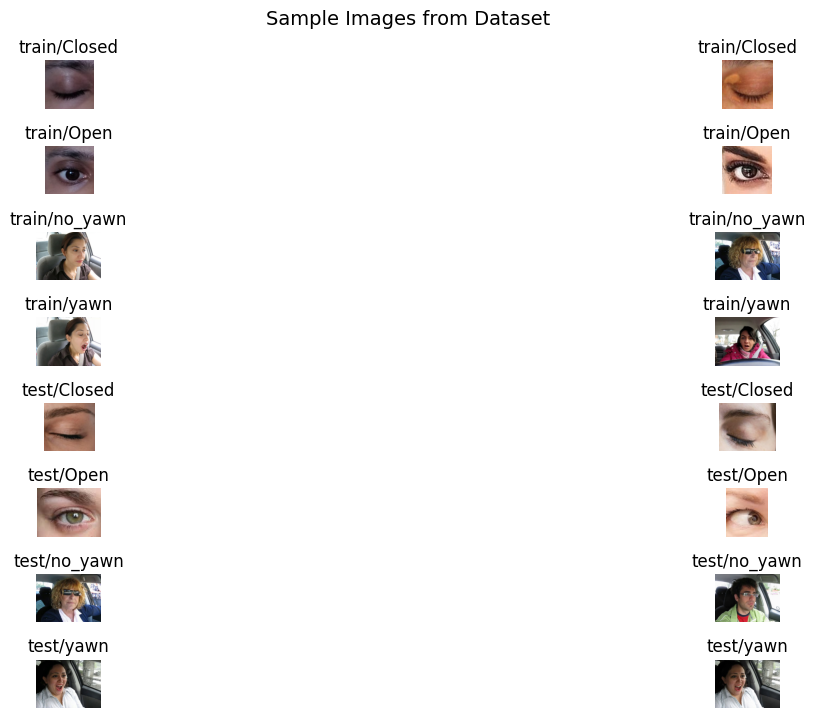

In [11]:
dataset_root = "/kaggle/input/yawn-eye-dataset-new/dataset_new"

plt.figure(figsize=(20, 7))
for idx, cls in enumerate(class_counts.keys()):
    cls_path = os.path.join(dataset_root, cls)  # directly join with dataset root
    if not os.path.exists(cls_path):
        print(f"Skipping missing folder: {cls_path}")
        continue

    img_files = [f for f in os.listdir(cls_path) if is_image_valid(os.path.join(cls_path, f))][:2]

    for i, img_file in enumerate(img_files):
        img_path = os.path.join(cls_path, img_file)
        img = Image.open(img_path)
        plt.subplot(len(class_counts), 2, idx * 2 + i + 1)
        plt.imshow(img)
        plt.title(f"{cls}")
        plt.axis('off')

plt.tight_layout()
plt.suptitle("Sample Images from Dataset", fontsize=14, y=1.02)
plt.show()

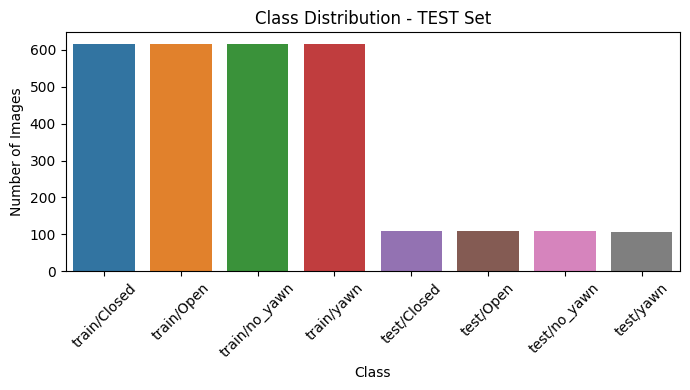

In [12]:
# Task 5: Plot class distribution
plt.figure(figsize=(7, 4))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()))
plt.title(f"Class Distribution - {split.upper()} Set")
plt.ylabel("Number of Images")
plt.xlabel("Class")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Loaded 2467 valid images.


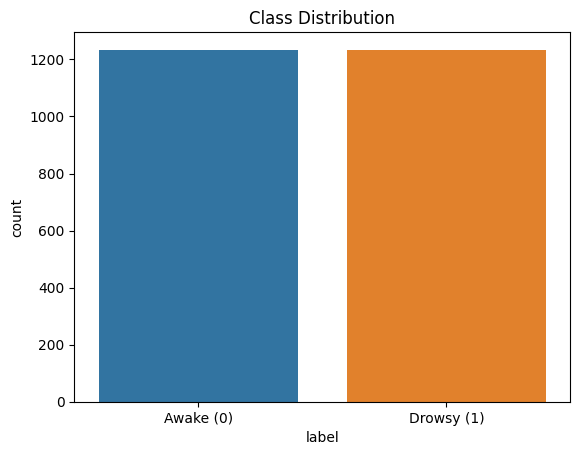

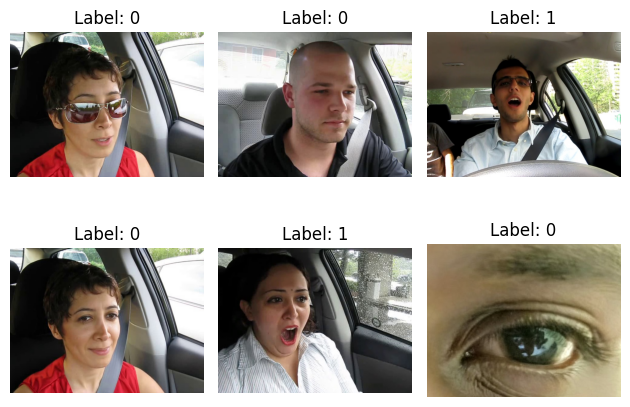

Preprocessing done. Shape: (2467, 96, 96, 3)
Train: 1726 | Val: 247 | Test: 494


In [13]:
# Evaluation Metrics
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
# Load dataset
yawn_eye_data = []
for cls in os.listdir(yawn_eye_base):
    cls_path = os.path.join(yawn_eye_base, cls)
    label = yawn_eye_map.get(cls, -1)
    if label == -1 or not os.path.isdir(cls_path):
        continue
    for img_file in os.listdir(cls_path):
        try:
            img_path = os.path.join(cls_path, img_file)
            Image.open(img_path).verify()
            yawn_eye_data.append([img_path, label])
        except: pass

df = pd.DataFrame(yawn_eye_data, columns=["image_path", "label"])
print(f"Loaded {len(df)} valid images.")

# Shuffle
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Plot distribution
sns.countplot(data=df, x="label")
plt.title("Class Distribution")
plt.xticks([0,1], ["Awake (0)", "Drowsy (1)"])
plt.show()

# Show sample images
for i in range(min(6, len(df))):
    img = Image.open(df.iloc[i]['image_path'])
    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(f"Label: {df.iloc[i]['label']}")
    plt.axis('off')
plt.tight_layout()
plt.show()

# Preprocess images
def preprocess(path, size=(96,96)):
    try:
        return np.array(Image.open(path).convert("RGB").resize(size)) / 255.0
    except: return None

X, y = [], []
for _, row in df.iterrows():
    img = preprocess(row['image_path'])
    if img is not None:
        X.append(img)
        y.append(row['label'])

X, y = np.array(X), np.array(y)
print("Preprocessing done. Shape:", X.shape)

# Split data (70/10/20)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=42)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

In [14]:
from tensorflow.keras.applications import VGG16, VGG19, InceptionV3, EfficientNetB0
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from sklearn.metrics import classification_report, confusion_matrix

# Dataset paths
train_dir = "/kaggle/input/yawn-eye-dataset-new/dataset_new/train"
test_dir  = "/kaggle/input/yawn-eye-dataset-new/dataset_new/test"

# Class mapping
yawn_eye_map = {"Closed": 1, "yawn": 1, "Open": 0, "no_yawn": 0}

# Function: load images & labels from directory
def load_data(base_dir):
    data = []
    for cls in os.listdir(base_dir):
        path = os.path.join(base_dir, cls)
        label = yawn_eye_map.get(cls, -1)
        if label == -1 or not os.path.isdir(path): continue
        for img in os.listdir(path):
            try:
                Image.open(os.path.join(path, img)).verify()
                data.append([os.path.join(path, img), label])
            except: pass
    return pd.DataFrame(data, columns=["image_path", "label"])

# Function: preprocess image
def preprocess(path, size=(96,96)):
    try:
        return np.array(Image.open(path).convert("RGB").resize(size)) / 255.0
    except: return None

# Load and preprocess train data
df_train = load_data(train_dir)
X_train, y_train = zip(*[(img, lbl) for path,lbl in df_train.values if (img:=preprocess(path)) is not None])
X_train, y_train = np.array(X_train), np.array(y_train)

# Load and preprocess test data
df_test = load_data(test_dir)
X_test, y_test = zip(*[(img, lbl) for path,lbl in df_test.values if (img:=preprocess(path)) is not None])
X_test, y_test = np.array(X_test), np.array(y_test)

print(f"Train: {len(X_train)} samples | Test: {len(X_test)} samples")

# Function: build model
def build_model(type="vgg16"):
    input_tensor = Input(shape=(96,96,3))
    if type in ["vgg16","vgg19","inception","efficientnet"]:
        base_cls = {"vgg16": VGG16, "vgg19": VGG19, "inception": InceptionV3, "efficientnet": EfficientNetB0}[type]
        base = base_cls(include_top=False, weights='imagenet', input_tensor=input_tensor)
        for l in base.layers: l.trainable = False
        x = GlobalAveragePooling2D()(base.output)
    else:
        x = Conv2D(32,3,activation='relu')(input_tensor)
        x = MaxPooling2D()(x)
        x = Conv2D(64,3,activation='relu')(x)
        x = GlobalAveragePooling2D()(x)
    x = Dense(64 if type!="shufflenet" else 32, activation='relu')(x)
    x = Dropout(0.3)(x)
    out = Dense(1, activation='sigmoid')(x)
    model = Model(inputs=input_tensor, outputs=out)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Build and train models
models = {name: build_model(name) for name in ["vgg16","vgg19","inception","efficientnet","squeezenet","shufflenet"]}
history = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    hist = model.fit(X_train, y_train, epochs=15, batch_size=32, verbose=1)
    history[name] = hist

print("\nAll models trained.")

# Evaluate each model on test set
for name, model in models.items():
    print(f"\nEvaluation - {name}:")
    preds = (model.predict(X_test) > 0.5).astype(int)
    print(classification_report(y_test, preds))
    cm = confusion_matrix(y_test, preds)
    print("Confusion matrix:\n", cm)

Train: 2467 samples | Test: 433 samples


I0000 00:00:1793500814.296750      40 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793500814.299811      40 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Training vgg16...
Epoch 1/15


I0000 00:00:1793500824.340620      92 service.cc:148] XLA service 0x78a8a400e770 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793500824.341505      92 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1793500824.341524      92 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1793500824.828523      92 cuda_dnn.cc:529] Loaded cuDNN version 90300


 5/78 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.4053 - loss: 0.8121

I0000 00:00:1793500828.955315      92 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


78/78 ━━━━━━━━━━━━━━━━━━━━ 12s 64ms/step - accuracy: 0.6021 - loss: 0.6478
Epoch 2/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.7641 - loss: 0.4646
Epoch 3/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.7970 - loss: 0.3993
Epoch 4/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.8213 - loss: 0.3609
Epoch 5/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.8291 - loss: 0.3410
Epoch 6/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.8470 - loss: 0.3271
Epoch 7/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.8493 - loss: 0.3195
Epoch 8/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.8624 - loss: 0.2939
Epoch 9/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.8639 - loss: 0.2804
Epoch 10/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.8874 - loss: 0.2667
Epoch 11/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.8883 - loss: 0.2625
Epoch 12/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.8861 - 

Epoch 1/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 21s 113ms/step - accuracy: 0.5461 - loss: 0.7089 - val_accuracy: 0.4965 - val_loss: 1.5783
Epoch 2/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.7340 - loss: 0.5149 - val_accuracy: 0.4965 - val_loss: 1.4323
Epoch 3/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.7931 - loss: 0.4196 - val_accuracy: 0.4988 - val_loss: 1.4698
Epoch 4/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8499 - loss: 0.3517 - val_accuracy: 0.6051 - val_loss: 0.9116
Epoch 5/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9152 - loss: 0.2135 - val_accuracy: 0.7829 - val_loss: 0.4778
Epoch 6/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9450 - loss: 0.1462 - val_accuracy: 0.7760 - val_loss: 0.4323
Epoch 7/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8312 - loss: 0.3657 - val_accuracy: 0.6674 - val_loss: 0.6840
Epoch 8/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9145 - loss: 0.2006 - val_accuracy: 0.9145 -

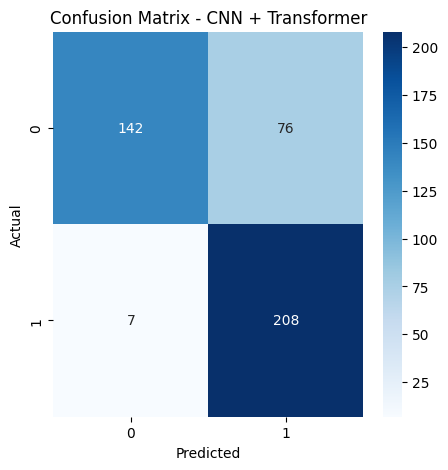

In [15]:
# ================= CNN + Transformer Hybrid =================

from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, BatchNormalization,
                                     Reshape, MultiHeadAttention, LayerNormalization,
                                     GlobalAveragePooling1D, Dense, Dropout)
from tensorflow.keras.models import Model

inputs = Input(shape=(96,96,3))

# CNN Feature Extraction
x = Conv2D(32, 3, activation='relu', padding='same')(inputs)
x = BatchNormalization()(x)
x = MaxPooling2D()(x)

x = Conv2D(64, 3, activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = MaxPooling2D()(x)

x = Conv2D(128, 3, activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = MaxPooling2D()(x)

# Convert feature map to sequence
x = Reshape((-1, 128))(x)

# Transformer Block
attn = MultiHeadAttention(num_heads=4, key_dim=32)(x, x)
x = LayerNormalization(epsilon=1e-6)(x + attn)

ffn = Dense(256, activation='relu')(x)
ffn = Dense(128)(ffn)
x = LayerNormalization(epsilon=1e-6)(x + ffn)

# Classification Head
x = GlobalAveragePooling1D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)

outputs = Dense(1, activation='sigmoid')(x)

cnn_transformer = Model(inputs, outputs)

cnn_transformer.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train
history = cnn_transformer.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=15,
    batch_size=32,
    verbose=1
)

# ================= Evaluation =================

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

# Predictions
pred = (cnn_transformer.predict(X_test) > 0.5).astype(int).flatten()

# Metrics
acc  = accuracy_score(y_test, pred)
prec = precision_score(y_test, pred)
rec  = recall_score(y_test, pred)
f1   = f1_score(y_test, pred)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\nClassification Report")
print(classification_report(y_test, pred))

# Confusion Matrix
plt.figure(figsize=(5,5))
sns.heatmap(confusion_matrix(y_test, pred),
            annot=True,
            fmt='d',
            cmap='Blues')
plt.title("Confusion Matrix - CNN + Transformer")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_101 (Conv2D) │ (None, 96, 96,    │        896 │ input_layer_7[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 96, 96,    │        128 │ conv2d_101[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 48, 48,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_102 (Conv2D) │ (None, 48, 48,    │     18,496 │ max_pooling2d_9[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        256 │ conv2d_102[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_10    │ (None, 24, 24,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_103 (Conv2D) │ (None, 24, 24,    │     73,856 │ max_pooling2d_10… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 24, 24,    │        512 │ conv2d_103[0][0]  │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_11    │ (None, 12, 12,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 144, 128)  │          0 │ max_pooling2d_11… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 144, 128)  │     66,048 │ reshape_1[0][0],  │
│ (MultiHeadAttentio… │                   │            │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 144, 128)  │          0 │ reshape_1[0][0],  │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 144, 128)  │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 144, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 144, 128)  │     32,896 │ dense_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 144, 128)  │          0 │ layer_normalizat… │
│                     │                   │            │ dense_17[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 144, 128)  │        256 │ add_3[0][0]     

 Total params: 243,265 (950.25 KB)

 Trainable params: 242,817 (948.50 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 18s 93ms/step - accuracy: 0.5453 - loss: 0.7255 - val_accuracy: 0.4965 - val_loss: 1.9987
Epoch 2/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.7124 - loss: 0.4854 - val_accuracy: 0.4965 - val_loss: 2.0971
Epoch 3/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8062 - loss: 0.3874 - val_accuracy: 0.5058 - val_loss: 1.3121
Epoch 4/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8026 - loss: 0.3740 - val_accuracy: 0.6605 - val_loss: 0.7288
Epoch 5/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8619 - loss: 0.3027 - val_accuracy: 0.6905 - val_loss: 0.6923
Epoch 6/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9095 - loss: 0.2341 - val_accuracy: 0.7390 - val_loss: 0.6266
Epoch 7/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8685 - loss: 0.3129 - val_accuracy: 0.8799 - val_loss: 0.3044
Epoch 8/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9310 - loss: 0.1803 - val_accuracy: 0.8915 - 

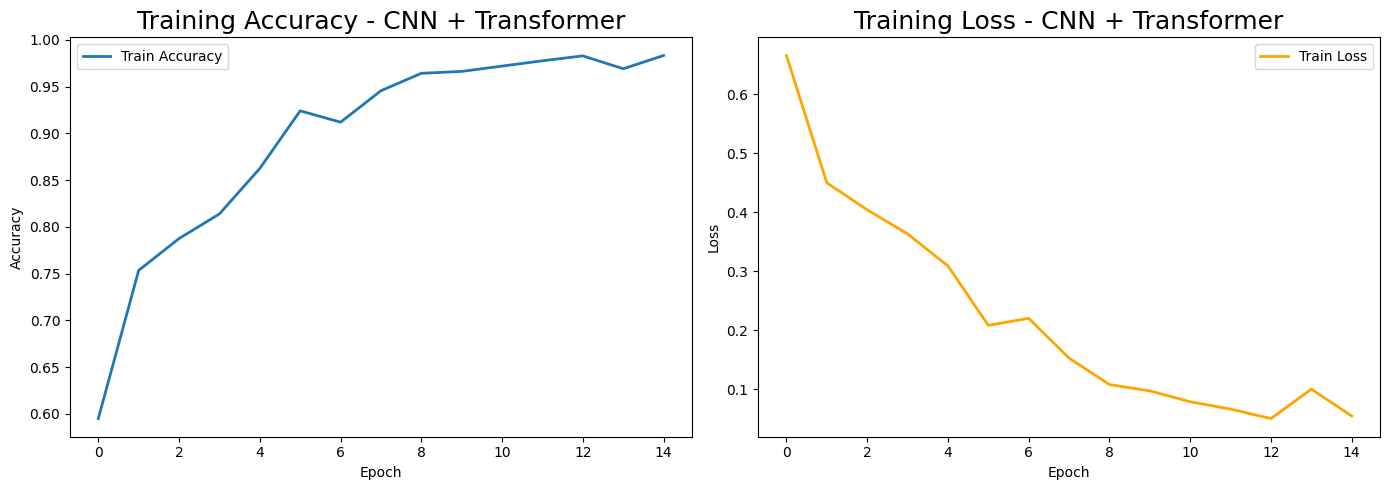

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step

TEST RESULTS
Accuracy  : 0.9584
Precision : 0.9539
Recall    : 0.9628
F1-Score  : 0.9583

Classification Report
              precision    recall  f1-score   support

           0       0.96      0.95      0.96       218
           1       0.95      0.96      0.96       215

    accuracy                           0.96       433
   macro avg       0.96      0.96      0.96       433
weighted avg       0.96      0.96      0.96       433



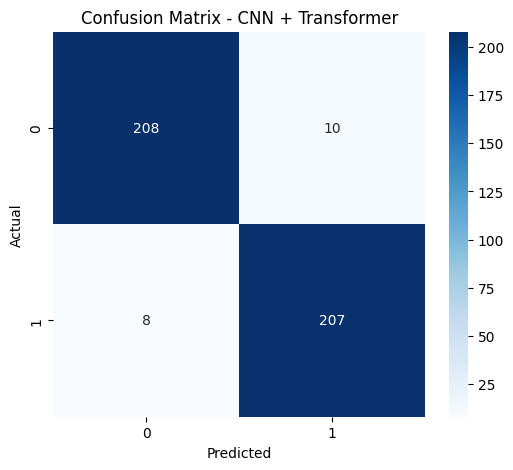


Epoch-wise Results
    Epoch  Train Accuracy  Train Loss  Validation Accuracy  Validation Loss
0       1        0.595055    0.665897             0.496536         1.998692
1       2        0.753547    0.449921             0.496536         2.097123
2       3        0.787596    0.404054             0.505774         1.312092
3       4        0.813944    0.363170             0.660508         0.728808
4       5        0.862586    0.308947             0.690531         0.692312
5       6        0.924199    0.208009             0.739030         0.626631
6       7        0.912039    0.219950             0.879908         0.304434
7       8        0.945683    0.152475             0.891455         0.292540
8       9        0.964329    0.107598             0.822171         0.450781
9      10        0.966356    0.096830             0.891455         0.254019
10     11        0.972031    0.078473             0.958430         0.124144
11     12        0.977706    0.065943             0.963049         0

In [16]:
# ============================================================
# CNN + Transformer Hybrid Model
# Training Accuracy & Loss Graphs + Evaluation Metrics
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, BatchNormalization,
    Reshape, MultiHeadAttention, LayerNormalization,
    GlobalAveragePooling1D, Dense, Dropout
)
from tensorflow.keras.models import Model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# MODEL ARCHITECTURE
# ============================================================

inputs = Input(shape=(96,96,3))

# CNN Feature Extraction
x = Conv2D(32, (3,3), activation='relu', padding='same')(inputs)
x = BatchNormalization()(x)
x = MaxPooling2D((2,2))(x)

x = Conv2D(64, (3,3), activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = MaxPooling2D((2,2))(x)

x = Conv2D(128, (3,3), activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = MaxPooling2D((2,2))(x)

# Convert Feature Maps into Sequence
x = Reshape((-1,128))(x)

# ============================================================
# TRANSFORMER BLOCK
# ============================================================

attn = MultiHeadAttention(
    num_heads=4,
    key_dim=32
)(x, x)

x = LayerNormalization(epsilon=1e-6)(x + attn)

ffn = Dense(256, activation='relu')(x)
ffn = Dense(128)(ffn)

x = LayerNormalization(epsilon=1e-6)(x + ffn)

# ============================================================
# CLASSIFICATION HEAD
# ============================================================

x = GlobalAveragePooling1D()(x)

x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)

outputs = Dense(1, activation='sigmoid')(x)

cnn_transformer = Model(inputs, outputs)

# ============================================================
# COMPILE MODEL
# ============================================================

cnn_transformer.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

cnn_transformer.summary()

# ============================================================
# TRAIN MODEL
# ============================================================

history = cnn_transformer.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=15,
    batch_size=32,
    verbose=1
)

# ============================================================
# TRAINING RESULTS
# ============================================================

train_acc = history.history['accuracy'][-1]
train_loss = history.history['loss'][-1]

val_acc = history.history['val_accuracy'][-1]
val_loss = history.history['val_loss'][-1]

print("\n==============================")
print("TRAINING RESULTS")
print("==============================")
print(f"Training Accuracy   : {train_acc:.4f}")
print(f"Training Loss       : {train_loss:.4f}")
print(f"Validation Accuracy : {val_acc:.4f}")
print(f"Validation Loss     : {val_loss:.4f}")

# ============================================================
# TRAINING ACCURACY & LOSS PLOTS
# ============================================================

epochs = range(len(history.history['accuracy']))

plt.figure(figsize=(14,5))

# Training Accuracy
plt.subplot(1,2,1)
plt.plot(
    epochs,
    history.history['accuracy'],
    linewidth=2,
    label='Train Accuracy'
)
plt.title('Training Accuracy - CNN + Transformer', fontsize=18)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Training Loss
plt.subplot(1,2,2)
plt.plot(
    epochs,
    history.history['loss'],
    linewidth=2,
    color='orange',
    label='Train Loss'
)
plt.title('Training Loss - CNN + Transformer', fontsize=18)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# ============================================================
# TEST PREDICTION
# ============================================================

y_pred_prob = cnn_transformer.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int).flatten()

# ============================================================
# PERFORMANCE METRICS
# ============================================================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\n==============================")
print("TEST RESULTS")
print("==============================")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report")
print(classification_report(y_test, y_pred))

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)
plt.title('Confusion Matrix - CNN + Transformer')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ============================================================
# EPOCH-WISE RESULTS TABLE
# ============================================================

results = pd.DataFrame({
    'Epoch': np.arange(1, len(history.history['accuracy'])+1),
    'Train Accuracy': history.history['accuracy'],
    'Train Loss': history.history['loss'],
    'Validation Accuracy': history.history['val_accuracy'],
    'Validation Loss': history.history['val_loss']
})

print("\nEpoch-wise Results")
print(results)

# Save Results
results.to_excel(
    "CNN_Transformer_Epochwise_Results.xlsx",
    index=False
)

# ============================================================
# FINAL PERFORMANCE SUMMARY
# ============================================================

summary = pd.DataFrame({
    'Metric': [
        'Training Accuracy',
        'Training Loss',
        'Validation Accuracy',
        'Validation Loss',
        'Testing Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ],
    'Value': [
        train_acc,
        train_loss,
        val_acc,
        val_loss,
        accuracy,
        precision,
        recall,
        f1
    ]
})

print("\nFinal Performance Summary")
print(summary)

summary.to_excel(
    "CNN_Transformer_Final_Performance.xlsx",
    index=False
)


Training and Evaluating: vgg16
Epoch 1/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 12s 120ms/step - accuracy: 0.6133 - loss: 0.6619 - val_accuracy: 0.7935 - val_loss: 0.4579
Epoch 2/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.7774 - loss: 0.4419 - val_accuracy: 0.8259 - val_loss: 0.3786
Epoch 3/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.7941 - loss: 0.3972 - val_accuracy: 0.8543 - val_loss: 0.3434
Epoch 4/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.8180 - loss: 0.3604 - val_accuracy: 0.8623 - val_loss: 0.3194
Epoch 5/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.8400 - loss: 0.3363 - val_accuracy: 0.8785 - val_loss: 0.2964
Epoch 6/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.8560 - loss: 0.3050 - val_accuracy: 0.8785 - val_loss: 0.2815
Epoch 7/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.8447 - loss: 0.3048 - val_accuracy: 0.8988 - val_loss: 0.2704
Epoch 8/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.8721 - loss:

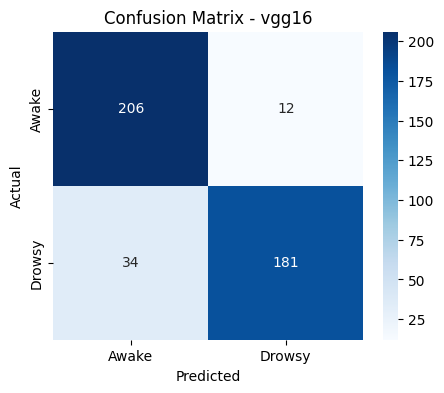

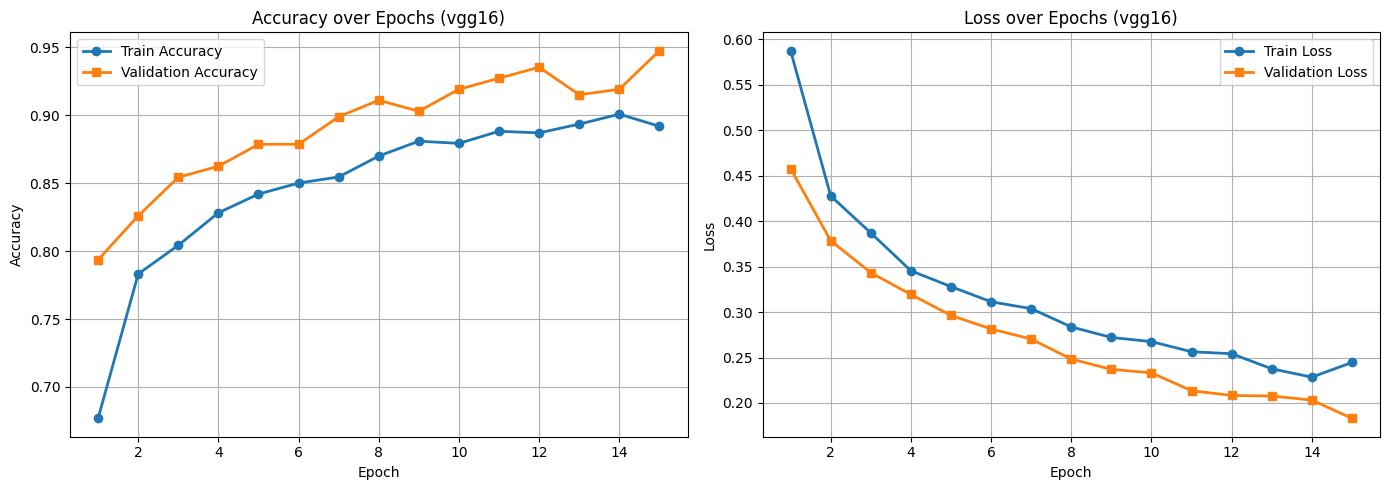


Training and Evaluating: vgg19
Epoch 1/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 11s 99ms/step - accuracy: 0.6009 - loss: 0.6578 - val_accuracy: 0.7328 - val_loss: 0.4506
Epoch 2/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.7798 - loss: 0.4390 - val_accuracy: 0.8381 - val_loss: 0.3778
Epoch 3/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 5s 69ms/step - accuracy: 0.8147 - loss: 0.3796 - val_accuracy: 0.8421 - val_loss: 0.3409
Epoch 4/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 6s 72ms/step - accuracy: 0.8385 - loss: 0.3535 - val_accuracy: 0.8057 - val_loss: 0.3375
Epoch 5/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step - accuracy: 0.8272 - loss: 0.3426 - val_accuracy: 0.8704 - val_loss: 0.2972
Epoch 6/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step - accuracy: 0.8286 - loss: 0.3301 - val_accuracy: 0.8826 - val_loss: 0.2785
Epoch 7/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step - accuracy: 0.8545 - loss: 0.2989 - val_accuracy: 0.8826 - val_loss: 0.2693
Epoch 8/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - accuracy: 0.8557 - loss: 

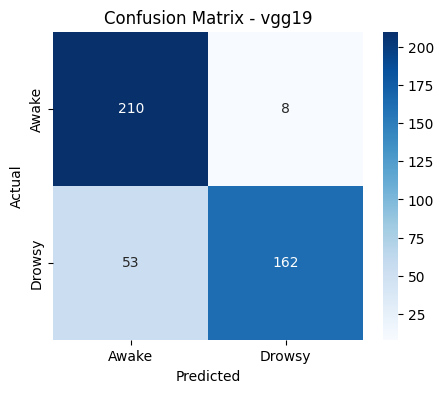

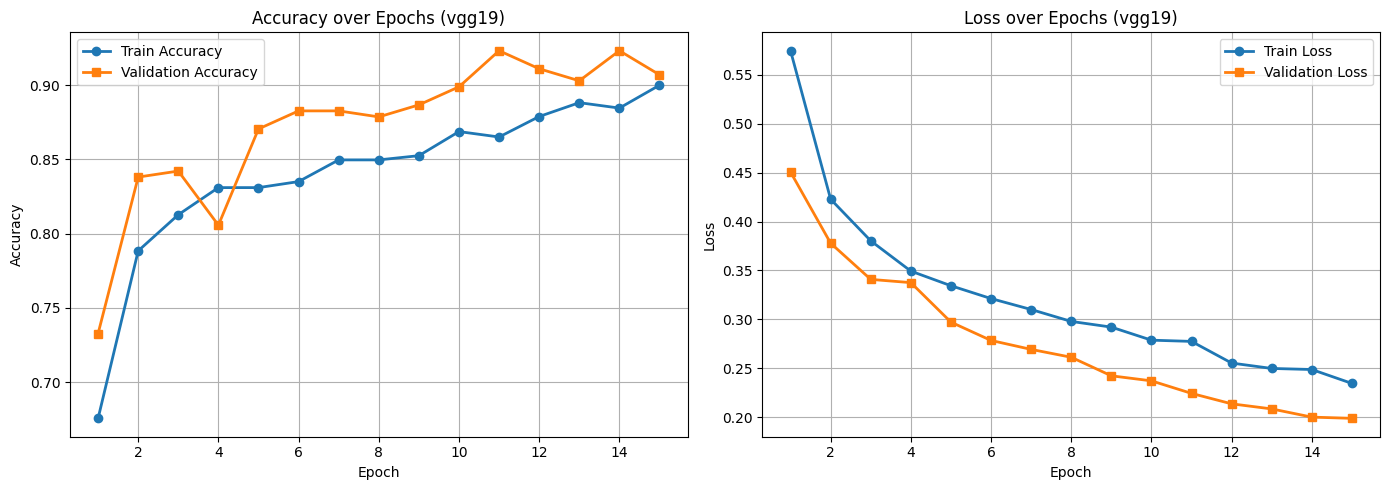


Training and Evaluating: inception
Epoch 1/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 31s 206ms/step - accuracy: 0.6642 - loss: 0.6157 - val_accuracy: 0.7976 - val_loss: 0.3756
Epoch 2/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8260 - loss: 0.3599 - val_accuracy: 0.8502 - val_loss: 0.2894
Epoch 3/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8628 - loss: 0.3009 - val_accuracy: 0.8785 - val_loss: 0.2389
Epoch 4/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8965 - loss: 0.2458 - val_accuracy: 0.9433 - val_loss: 0.1836
Epoch 5/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8959 - loss: 0.2176 - val_accuracy: 0.9393 - val_loss: 0.1685
Epoch 6/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9194 - loss: 0.1968 - val_accuracy: 0.9798 - val_loss: 0.1266
Epoch 7/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9299 - loss: 0.1693 - val_accuracy: 0.9717 - val_loss: 0.0959
Epoch 8/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9510 - l

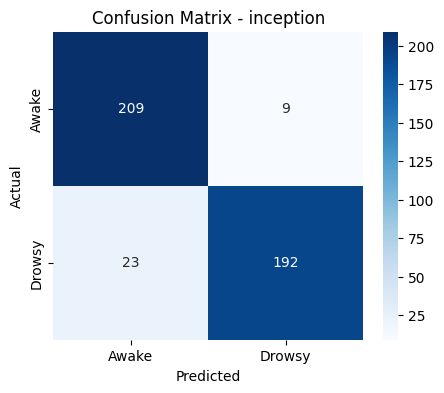

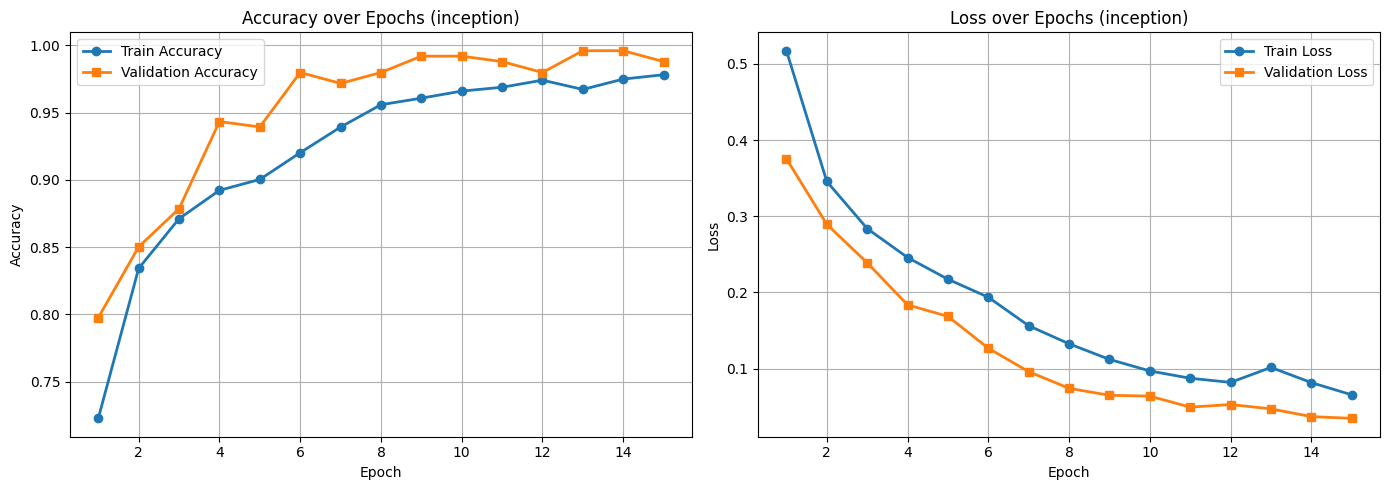


Training and Evaluating: efficientnet
Epoch 1/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 43s 257ms/step - accuracy: 0.4938 - loss: 0.7098 - val_accuracy: 0.4980 - val_loss: 0.6940
Epoch 2/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.5074 - loss: 0.6957 - val_accuracy: 0.5020 - val_loss: 0.6931
Epoch 3/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5101 - loss: 0.6932 - val_accuracy: 0.4980 - val_loss: 0.6931
Epoch 4/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4815 - loss: 0.6932 - val_accuracy: 0.4980 - val_loss: 0.6931
Epoch 5/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5102 - loss: 0.6931 - val_accuracy: 0.4980 - val_loss: 0.6932
Epoch 6/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5122 - loss: 0.6931 - val_accuracy: 0.4980 - val_loss: 0.6932
Epoch 7/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4960 - loss: 0.6932 - val_accuracy: 0.4980 - val_loss: 0.6932
Epoch 8/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5131 

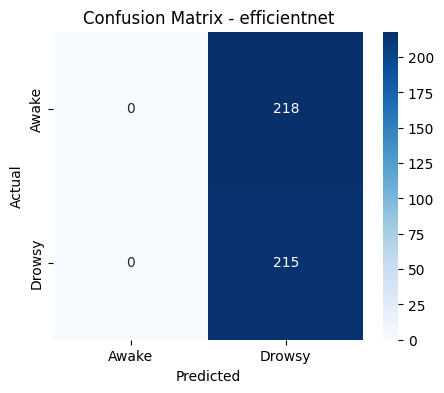

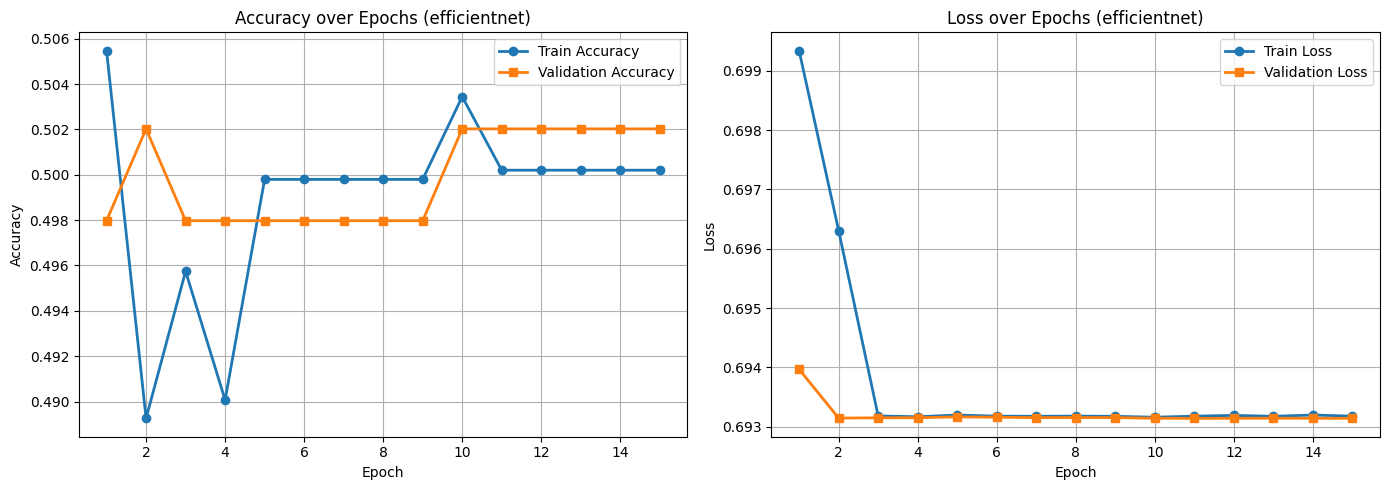


Training and Evaluating: squeezenet
Epoch 1/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.4998 - loss: 0.6942 - val_accuracy: 0.5425 - val_loss: 0.6919
Epoch 2/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4921 - loss: 0.6915 - val_accuracy: 0.4858 - val_loss: 0.6881
Epoch 3/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5283 - loss: 0.6836 - val_accuracy: 0.5344 - val_loss: 0.6797
Epoch 4/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5449 - loss: 0.6694 - val_accuracy: 0.5547 - val_loss: 0.6784
Epoch 5/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5785 - loss: 0.6636 - val_accuracy: 0.5344 - val_loss: 0.6576
Epoch 6/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5830 - loss: 0.6515 - val_accuracy: 0.5789 - val_loss: 0.6617
Epoch 7/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6017 - loss: 0.6529 - val_accuracy: 0.6032 - val_loss: 0.6443
Epoch 8/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6142 - loss: 0.6

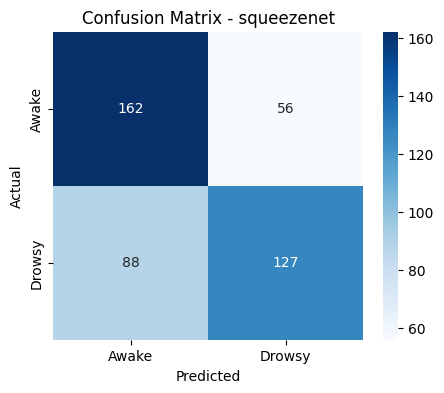

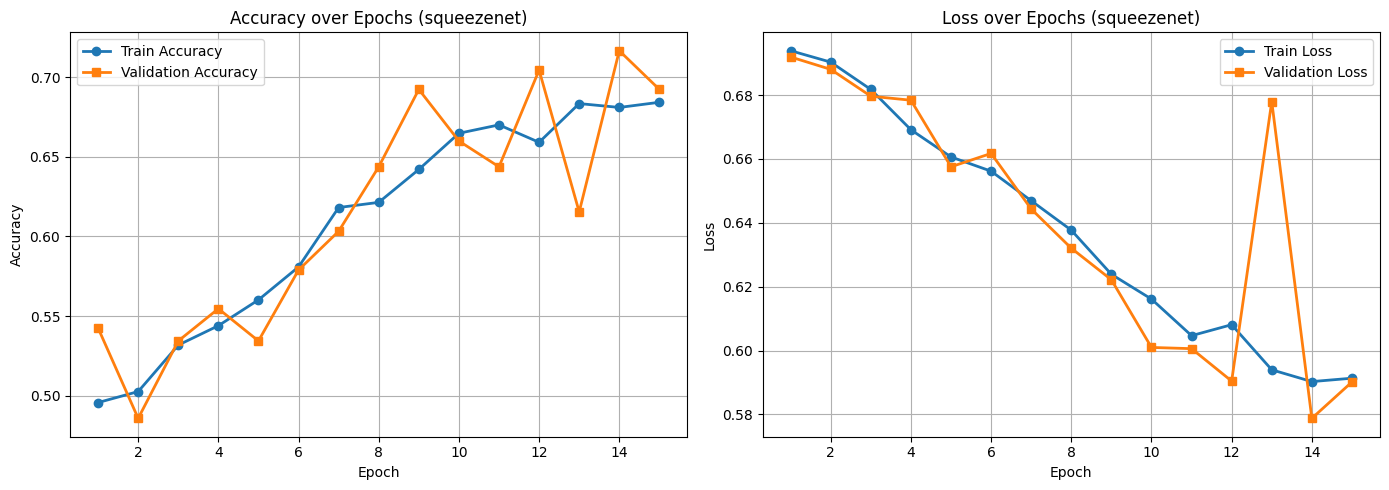


Training and Evaluating: shufflenet
Epoch 1/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.5066 - loss: 0.6943 - val_accuracy: 0.5061 - val_loss: 0.6932
Epoch 2/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5079 - loss: 0.6918 - val_accuracy: 0.4777 - val_loss: 0.6903
Epoch 3/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5278 - loss: 0.6873 - val_accuracy: 0.4413 - val_loss: 0.6919
Epoch 4/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5275 - loss: 0.6827 - val_accuracy: 0.5061 - val_loss: 0.6766
Epoch 5/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5407 - loss: 0.6737 - val_accuracy: 0.5020 - val_loss: 0.6741
Epoch 6/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5634 - loss: 0.6615 - val_accuracy: 0.5628 - val_loss: 0.6614
Epoch 7/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5675 - loss: 0.6568 - val_accuracy: 0.5506 - val_loss: 0.6569
Epoch 8/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5710 - loss: 0.6

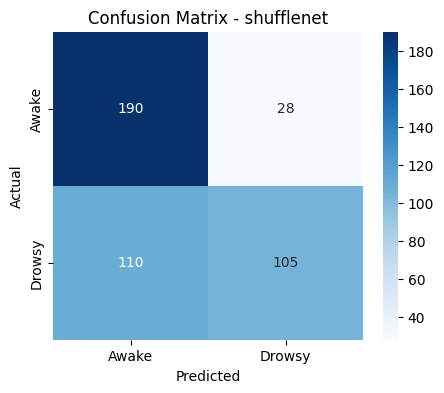

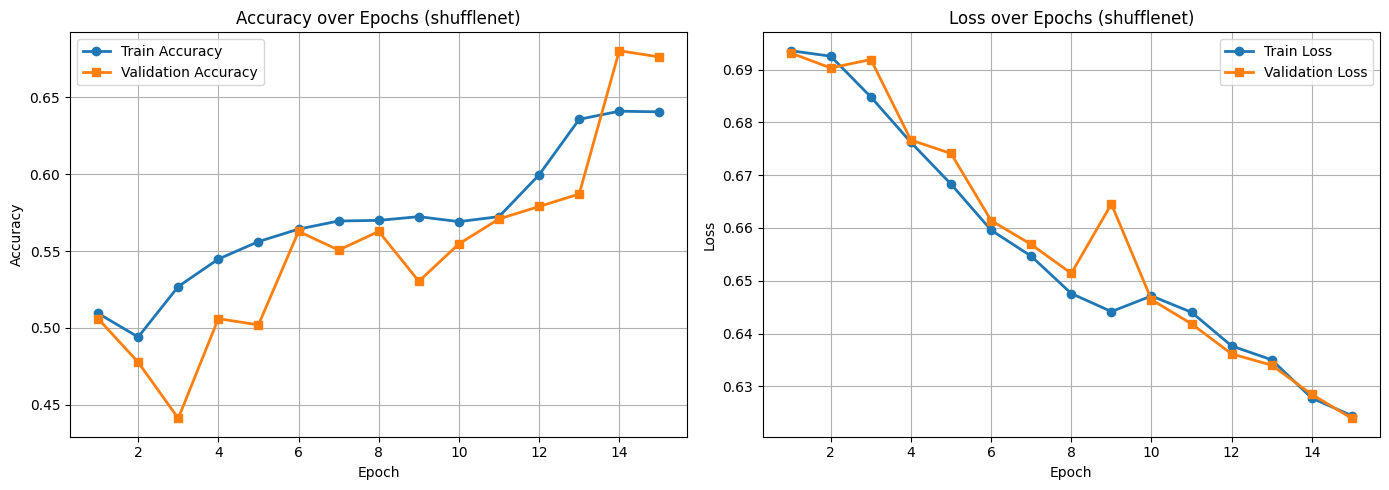


Training and Evaluating: cnn_vit
Epoch 1/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 19s 98ms/step - accuracy: 0.5378 - loss: 0.7187 - val_accuracy: 0.5020 - val_loss: 1.5705
Epoch 2/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7461 - loss: 0.4915 - val_accuracy: 0.5020 - val_loss: 1.6264
Epoch 3/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8129 - loss: 0.3899 - val_accuracy: 0.5020 - val_loss: 1.4489
Epoch 4/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8510 - loss: 0.3253 - val_accuracy: 0.5466 - val_loss: 0.9909
Epoch 5/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9130 - loss: 0.2341 - val_accuracy: 0.5870 - val_loss: 0.8170
Epoch 6/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9333 - loss: 0.1708 - val_accuracy: 0.7895 - val_loss: 0.4197
Epoch 7/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9476 - loss: 0.1383 - val_accuracy: 0.8462 - val_loss: 0.3576
Epoch 8/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9712 - loss

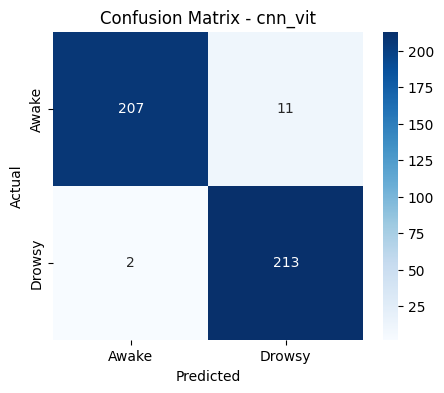

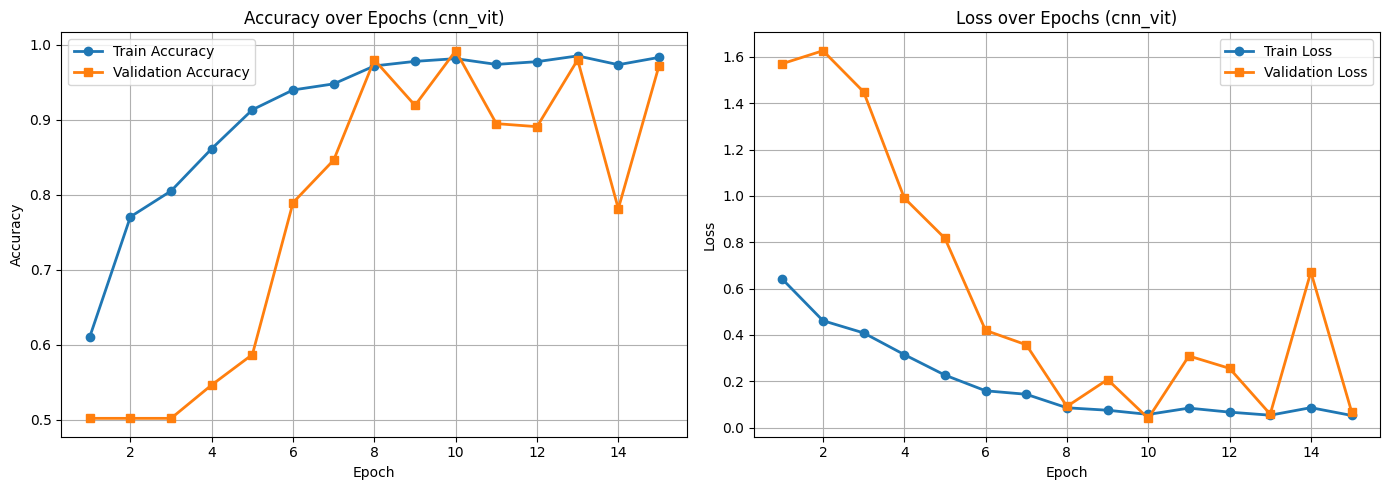


Final results:
           Model  Train Loss  Test Loss  Train Acc  Test Acc  Accuracy  \
0         vgg16    0.198568   0.245506   0.930280  0.893764  0.893764   
1         vgg19    0.230151   0.303100   0.889339  0.859122  0.859122   
2     inception    0.040056   0.199145   0.989866  0.926097  0.926097   
3  efficientnet    0.693159   0.693197   0.500203  0.496536  0.496536   
4    squeezenet    0.601309   0.600058   0.671666  0.667436  0.667436   
5    shufflenet    0.615302   0.618003   0.674098  0.681293  0.681293   
6       cnn_vit    0.054387   0.100092   0.983786  0.969977  0.969977   

   Precision    Recall        F1  
0   0.937824  0.841860  0.887255  
1   0.952941  0.753488  0.841558  
2   0.955224  0.893023  0.923077  
3   0.496536  1.000000  0.663580  
4   0.693989  0.590698  0.638191  
5   0.789474  0.488372  0.603448  
6   0.950893  0.990698  0.970387  


In [17]:
# ============================================================
# ALL MODELS: TRAIN + VALIDATION CURVES (Figure 3, panels a-g)
# ============================================================
from tensorflow.keras.applications import VGG16, VGG19, InceptionV3, EfficientNetB0
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D,
                                      Dense, Dropout, BatchNormalization, Reshape,
                                      MultiHeadAttention, LayerNormalization,
                                      GlobalAveragePooling1D)
from tensorflow.keras.models import Model
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix)

# ---------- Build the 6 baseline / transfer-learning models ----------
def build_model(type="vgg16"):
    input_tensor = Input(shape=(96,96,3))
    if type in ["vgg16","vgg19","inception","efficientnet"]:
        base_cls = {"vgg16": VGG16, "vgg19": VGG19,
                     "inception": InceptionV3, "efficientnet": EfficientNetB0}[type]
        base = base_cls(include_top=False, weights='imagenet', input_tensor=input_tensor)
        for l in base.layers:
            l.trainable = False
        x = GlobalAveragePooling2D()(base.output)
    else:  # squeezenet / shufflenet stand-ins
        x = Conv2D(32,3,activation='relu')(input_tensor)
        x = MaxPooling2D()(x)
        x = Conv2D(64,3,activation='relu')(x)
        x = GlobalAveragePooling2D()(x)
    x = Dense(64 if type != "shufflenet" else 32, activation='relu')(x)
    x = Dropout(0.3)(x)
    out = Dense(1, activation='sigmoid')(x)
    model = Model(inputs=input_tensor, outputs=out)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# ---------- Build the proposed CNN + Transformer (CNN-ViT) model ----------
def build_cnn_vit():
    inputs = Input(shape=(96,96,3))
    x = Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = BatchNormalization()(x); x = MaxPooling2D()(x)
    x = Conv2D(64, 3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x); x = MaxPooling2D()(x)
    x = Conv2D(128, 3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x); x = MaxPooling2D()(x)
    x = Reshape((-1, 128))(x)
    attn = MultiHeadAttention(num_heads=4, key_dim=32)(x, x)
    x = LayerNormalization(epsilon=1e-6)(x + attn)
    ffn = Dense(256, activation='relu')(x)
    ffn = Dense(128)(ffn)
    x = LayerNormalization(epsilon=1e-6)(x + ffn)
    x = GlobalAveragePooling1D()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.3)(x)
    outputs = Dense(1, activation='sigmoid')(x)
    model = Model(inputs, outputs)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# ---------- All 7 models, in Figure 3 panel order (a)-(g) ----------
model_names = ["vgg16", "vgg19", "inception", "efficientnet", "squeezenet", "shufflenet"]
models  = {name: build_model(name) for name in model_names}
models["cnn_vit"] = build_cnn_vit()   # panel (g)

results, history, y_preds = [], {}, {}

for name, model in models.items():
    print("\n" + "="*60)
    print(f"Training and Evaluating: {name}")
    print("="*60)

    hist = model.fit(
        X_train, y_train,
        epochs=15,
        batch_size=32,
        validation_data=(X_val, y_val),   # <-- real held-out validation set
        verbose=1
    )
    history[name] = hist

    # ---- Final evaluation on the untouched test set ----
    train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
    test_loss, test_acc   = model.evaluate(X_test, y_test, verbose=0)
    y_prob = model.predict(X_test, verbose=0)
    y_pred = (y_prob > 0.5).astype(int)
    y_preds[name] = y_pred

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec  = recall_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred)
    results.append([name, train_loss, test_loss, train_acc, test_acc, acc, prec, rec, f1])

    print(f"\nTrain Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")
    print(classification_report(y_test, y_pred))

    # ---- Confusion matrix ----
    plt.figure(figsize=(5,4))
    sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Awake', 'Drowsy'],
    yticklabels=['Awake', 'Drowsy']
    )
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.savefig(f"cm_{name}.png", dpi=300, bbox_inches='tight')
    plt.show()
    # ---- Training vs Validation curves (this is Figure 3) ----
    epochs_r = range(1, len(hist.history['loss']) + 1)
    plt.figure(figsize=(14,5))

    plt.subplot(1,2,1)
    plt.plot(epochs_r, hist.history['accuracy'], marker='o', linewidth=2, label='Train Accuracy')
    plt.plot(epochs_r, hist.history['val_accuracy'], marker='s', linewidth=2, label='Validation Accuracy')
    plt.title(f'Accuracy over Epochs ({name})')
    plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(True)

    plt.subplot(1,2,2)
    plt.plot(epochs_r, hist.history['loss'], marker='o', linewidth=2, label='Train Loss')
    plt.plot(epochs_r, hist.history['val_loss'], marker='s', linewidth=2, label='Validation Loss')
    plt.title(f'Loss over Epochs ({name})')
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(True)

    plt.tight_layout()
    plt.savefig(f"fig3_{name}.png", dpi=300, bbox_inches='tight')
    plt.show()

results_df = pd.DataFrame(results, columns=["Model","Train Loss","Test Loss",
                                             "Train Acc","Test Acc","Accuracy",
                                             "Precision","Recall","F1"])
print("\nFinal results:\n", results_df)

In [18]:
   from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
   from sklearn.model_selection import StratifiedKFold

In [19]:
for name in ["X", "y", "build_cnn_vit", "yawn_eye_base"]:
    print(name, "->", "defined" if name in dir() else "MISSING")

X -> defined
y -> defined
build_cnn_vit -> defined
yawn_eye_base -> defined


In [20]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_results = []

for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    print(f"\n===== Fold {fold_idx}/5 =====")
    X_tr, X_va = X[train_idx], X[val_idx]
    y_tr, y_va = y[train_idx], y[val_idx]

    model = build_cnn_vit()  # fresh, untrained model each fold
    model.fit(X_tr, y_tr, epochs=15, batch_size=32,
              validation_data=(X_va, y_va), verbose=1)

    y_prob = model.predict(X_va, verbose=0)
    y_pred = (y_prob > 0.5).astype(int)

    acc = accuracy_score(y_va, y_pred)
    prec = precision_score(y_va, y_pred)
    rec = recall_score(y_va, y_pred)
    f1 = f1_score(y_va, y_pred)
    fold_results.append([fold_idx, acc, prec, rec, f1])
    print(f"Fold {fold_idx} -> Acc: {acc:.4f}, Prec: {prec:.4f}, Rec: {rec:.4f}, F1: {f1:.4f}")

fold_df = pd.DataFrame(fold_results, columns=["Fold","Accuracy","Precision","Recall","F1"])
print("\nPer-fold results:\n", fold_df)
print("\nMean ± Std:")
print(fold_df[["Accuracy","Precision","Recall","F1"]].agg(['mean','std']))


===== Fold 1/5 =====
Epoch 1/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 19s 137ms/step - accuracy: 0.5680 - loss: 0.7190 - val_accuracy: 0.5000 - val_loss: 1.7282
Epoch 2/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.7495 - loss: 0.5033 - val_accuracy: 0.5000 - val_loss: 1.9830
Epoch 3/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.7649 - loss: 0.4461 - val_accuracy: 0.5000 - val_loss: 2.0466
Epoch 4/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8031 - loss: 0.4056 - val_accuracy: 0.4777 - val_loss: 1.0104
Epoch 5/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8164 - loss: 0.3835 - val_accuracy: 0.6802 - val_loss: 0.6672
Epoch 6/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8819 - loss: 0.2777 - val_accuracy: 0.6862 - val_loss: 0.8024
Epoch 7/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9180 - loss: 0.2276 - val_accuracy: 0.8016 - val_loss: 0.4114
Epoch 8/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9512 - loss: 0.1536 - 

In [21]:
import tensorflow as tf
import numpy as np
import time

print("Step 0: checking prerequisites...")
assert 'cnn_transformer' in dir(), "cnn_transformer not defined — load/train it first"
assert 'X_test' in dir(), "X_test not defined — run the data-loading cell first"
print("OK — both are defined. Proceeding.\n")

# ---------------- FLOPs ----------------
print("Step 1: FLOPs")
try:
    @tf.function
    def model_fn(x):
        return cnn_transformer(x)
    concrete = model_fn.get_concrete_function(
        tf.TensorSpec([1] + list(cnn_transformer.input_shape[1:]), tf.float32)
    )
    from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2
    frozen = convert_variables_to_constants_v2(concrete)
    flops = tf.compat.v1.profiler.profile(
        graph=frozen.graph,
        options=tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
    ).total_float_ops
    print(f"RESULT_FLOPS = {flops}")
except Exception as e:
    print(f"FLOPS_FAILED: {repr(e)}")

# ---------------- Inference time & FPS ----------------
print("\nStep 2: Inference time")
try:
    sample = X_test[:1].astype("float32")
    _ = cnn_transformer.predict(sample, verbose=0)  # warm-up
    n = 50
    t0 = time.time()
    for _ in range(n):
        _ = cnn_transformer.predict(sample, verbose=0)
    t1 = time.time()
    print(f"RESULT_INFERENCE_MS = {((t1-t0)/n)*1000}")
    print(f"RESULT_FPS = {n/(t1-t0)}")
except Exception as e:
    print(f"INFERENCE_FAILED: {repr(e)}")

# ---------------- Peak memory ----------------
print("\nStep 3: Peak memory")
try:
    if tf.config.list_physical_devices('GPU'):
        tf.config.experimental.reset_memory_stats('GPU:0')
        _ = cnn_transformer.predict(sample, verbose=0)
        peak = tf.config.experimental.get_memory_info('GPU:0')['peak']
        print(f"RESULT_PEAK_MEM_MB = {peak/(1024**2)}")
    else:
        print("NO_GPU_DETECTED")
except Exception as e:
    print(f"MEMORY_FAILED: {repr(e)}")

print("\nDONE.")

Step 0: checking prerequisites...
OK — both are defined. Proceeding.

Step 1: FLOPs


I0000 00:00:1793501798.537778      40 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1793501798.537953      40 single_machine.cc:361] Starting new session
I0000 00:00:1793501798.552847      40 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793501798.554448      40 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          
-account_displayed_op_only  true
-select                     float_ops
-output                     stdout:

==================Model Analysis Report======================

Doc:
scope: The nodes in the model graph are organized by their names, which is hierarchical like filesystem.
flops: Number of float operations. Note: Please read the implementation for the math behind it.

Profi


Running LIME XAI for CNN-TRANSFORMER


  0%|          | 0/1000 [00:00<?, ?it/s]

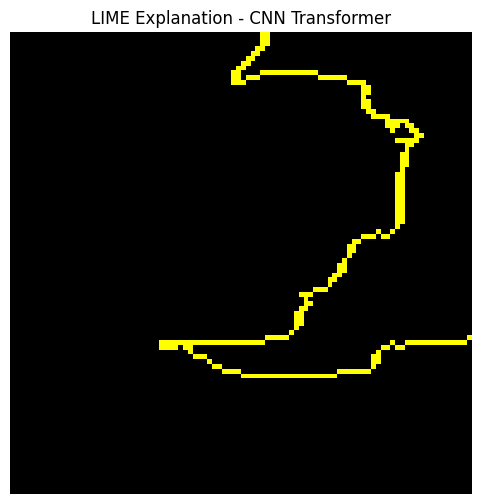


LIME Feature Analysis Table
             Model  Positive Feature %  Negative Feature %
0  CNN-Transformer               100.0                 0.0


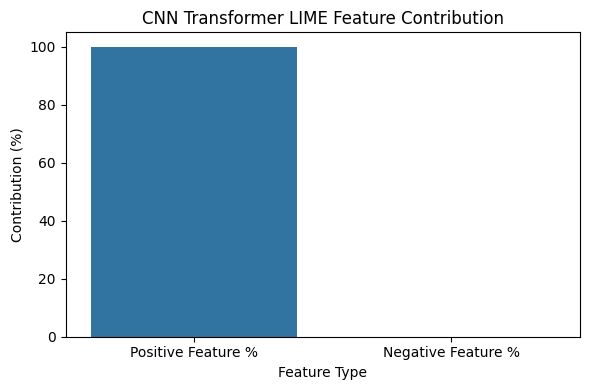

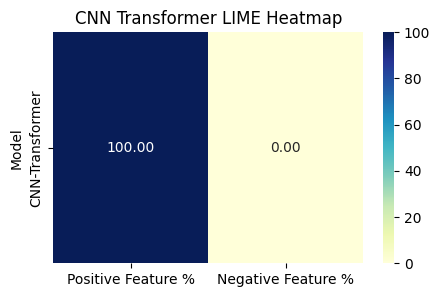


CNN-TRANSFORMER LIME ANALYSIS COMPLETED


In [22]:
# ============================================================
# LIME XAI FEATURE ANALYSIS FOR CNN-TRANSFORMER
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from lime import lime_image
from skimage.segmentation import mark_boundaries

# ============================================================
# STORE RESULTS
# ============================================================

xai_results = []

print("\n================================================")
print("Running LIME XAI for CNN-TRANSFORMER")
print("================================================")

# ============================================================
# TEST IMAGE
# ============================================================

image = X_test[0]

# ============================================================
# PREDICTION FUNCTION
# ============================================================

def predict_fn(images):

    images = np.array(images).astype(np.float32)

    preds = cnn_transformer.predict(
        images,
        verbose=0
    )

    preds = np.concatenate(
        [1-preds, preds],
        axis=1
    )

    return preds

# ============================================================
# CREATE LIME EXPLAINER
# ============================================================

explainer = lime_image.LimeImageExplainer()

# ============================================================
# GENERATE EXPLANATION
# ============================================================

explanation = explainer.explain_instance(
    image.astype('double'),
    predict_fn,
    top_labels=2,
    hide_color=0,
    num_samples=1000
)

# ============================================================
# FEATURE IMPORTANCE ANALYSIS
# ============================================================

weights = explanation.local_exp[1]

positive_weights = [
    w[1] for w in weights
    if w[1] > 0
]

negative_weights = [
    abs(w[1]) for w in weights
    if w[1] < 0
]

positive_score = np.sum(positive_weights)
negative_score = np.sum(negative_weights)

total_score = positive_score + negative_score

positive_percent = (
    positive_score / total_score
) * 100 if total_score != 0 else 0

negative_percent = (
    negative_score / total_score
) * 100 if total_score != 0 else 0

# ============================================================
# SAVE RESULTS
# ============================================================

xai_results.append([
    "CNN-Transformer",
    positive_percent,
    negative_percent
])

# ============================================================
# LIME VISUALIZATION
# ============================================================

temp, mask = explanation.get_image_and_mask(
    label=1,
    positive_only=True,
    hide_rest=False,
    num_features=10,
    min_weight=0.01
)

plt.figure(figsize=(6,6))

plt.imshow(
    mark_boundaries(temp/255.0, mask)
)

plt.title(
    "LIME Explanation - CNN Transformer"
)

plt.axis("off")
plt.show()

# ============================================================
# RESULTS TABLE
# ============================================================

xai_df = pd.DataFrame(
    xai_results,
    columns=[
        "Model",
        "Positive Feature %",
        "Negative Feature %"
    ]
)

print("\nLIME Feature Analysis Table")
print(xai_df)

# ============================================================
# BAR CHART
# ============================================================

xai_melt = xai_df.melt(
    id_vars="Model",
    value_vars=[
        "Positive Feature %",
        "Negative Feature %"
    ],
    var_name="Feature Type",
    value_name="Contribution"
)

plt.figure(figsize=(6,4))

sns.barplot(
    data=xai_melt,
    x="Feature Type",
    y="Contribution"
)

plt.title(
    "CNN Transformer LIME Feature Contribution"
)

plt.ylabel("Contribution (%)")

plt.tight_layout()
plt.show()

# ============================================================
# HEATMAP
# ============================================================

plt.figure(figsize=(5,3))

sns.heatmap(
    xai_df.set_index("Model"),
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)

plt.title(
    "CNN Transformer LIME Heatmap"
)

plt.show()

print("\n================================================")
print("CNN-TRANSFORMER LIME ANALYSIS COMPLETED")
print("================================================")

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

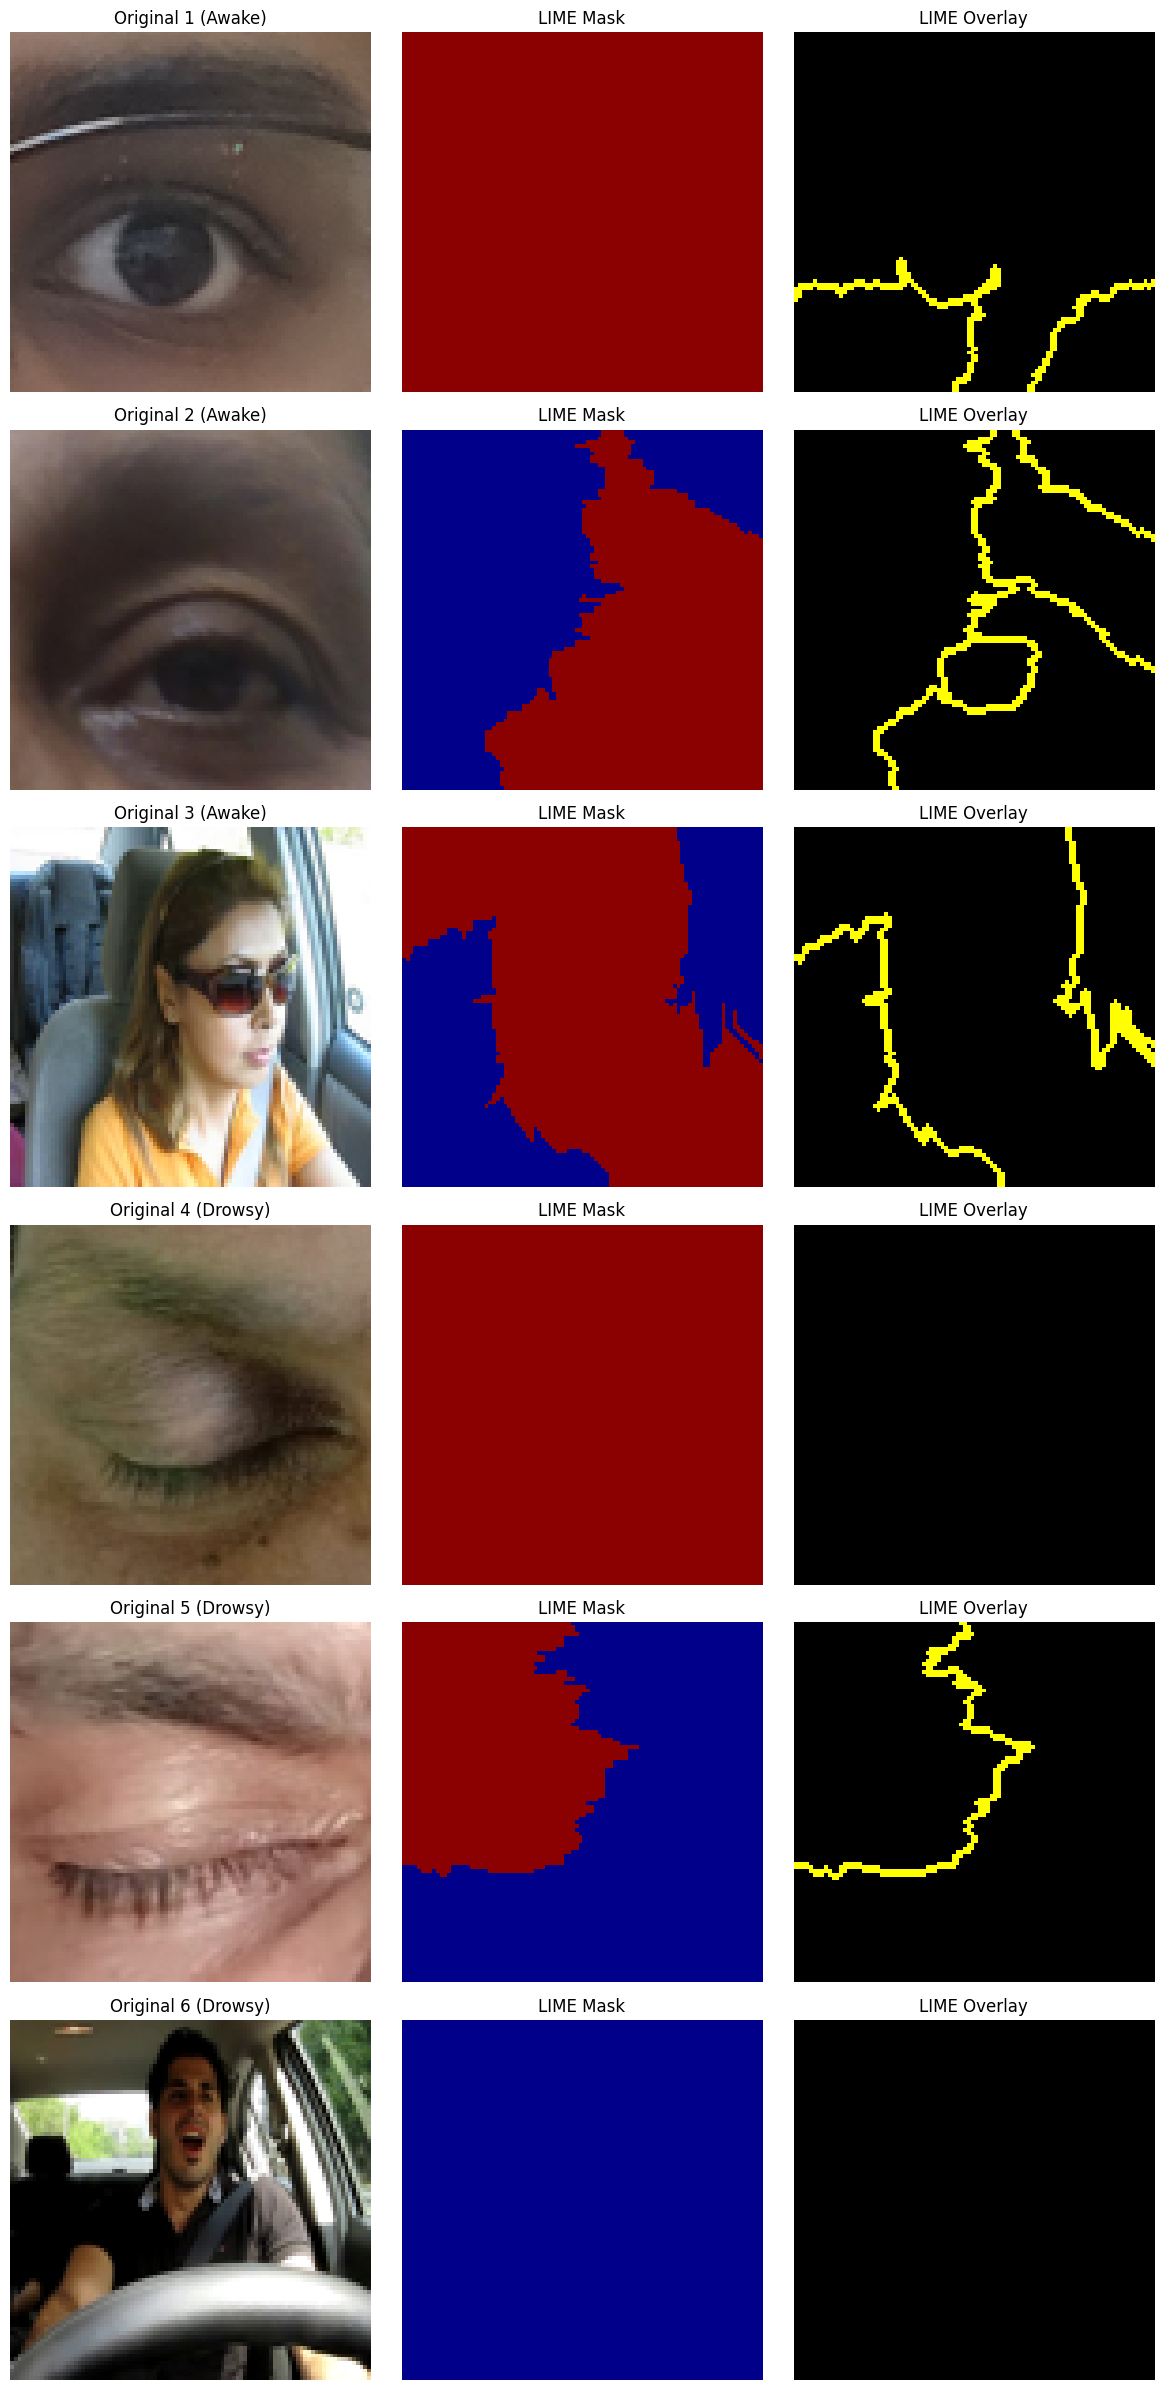

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from lime import lime_image
from skimage.segmentation import mark_boundaries

# Prediction function
def predict_fn(images):
    images = np.array(images).astype(np.float32)
    preds = cnn_transformer.predict(images, verbose=0)
    preds = np.concatenate([1 - preds, preds], axis=1)
    return preds

explainer = lime_image.LimeImageExplainer()

# Fixed colormap: 0 -> dark red, 1 -> dark blue
mask_cmap = ListedColormap(["#8B0000", "#00008B"])

# Pick N examples from each class (0 = Awake, 1 = Drowsy)
n_per_class = 3
awake_indices = np.where(y_test == 0)[0]
drowsy_indices = np.where(y_test == 1)[0]

sample_indices = list(
    np.random.choice(awake_indices, size=min(n_per_class, len(awake_indices)), replace=False)
) + list(
    np.random.choice(drowsy_indices, size=min(n_per_class, len(drowsy_indices)), replace=False)
)
sample_labels = ["Awake"] * n_per_class + ["Drowsy"] * n_per_class

n = len(sample_indices)
fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))
if n == 1:
    axes = axes.reshape(1, 3)

for row, (idx, class_label) in enumerate(zip(sample_indices, sample_labels)):
    image = X_test[idx]

    explanation = explainer.explain_instance(
        image.astype('double'),
        predict_fn,
        top_labels=2,
        hide_color=0,
        num_samples=1000
    )

    # --- Column 1: Original ---
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original {row + 1} ({class_label})")
    axes[row, 0].axis('off')

    # --- Column 2: LIME Mask ---
    _, mask = explanation.get_image_and_mask(
        label=1,
        positive_only=False,
        hide_rest=False,
        num_features=10,
        min_weight=0.01
    )
    binary_mask = (mask > 0).astype(int)
    axes[row, 1].imshow(binary_mask, cmap=mask_cmap, vmin=0, vmax=1)
    axes[row, 1].set_title("LIME Mask")
    axes[row, 1].axis('off')

    # --- Column 3: LIME Overlay ---
    black_bg = np.zeros_like(image)
    overlay = mark_boundaries(black_bg, mask, color=(1, 1, 0), mode='thick')
    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title("LIME Overlay")
    axes[row, 2].axis('off')

plt.tight_layout()
plt.show()



Running SHAP XAI for CNN-TRANSFORMER


PartitionExplainer explainer: 11it [00:26,  3.34s/it]                        

SHAP values generated successfully.


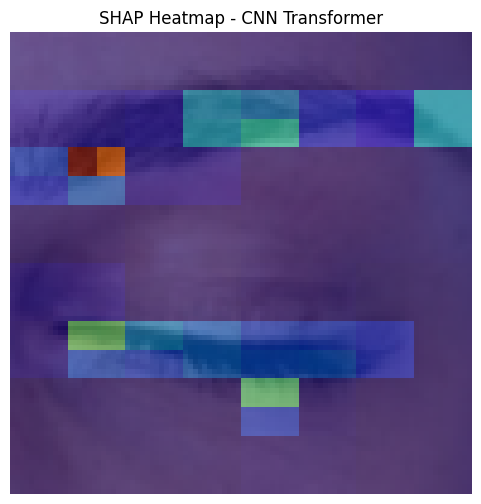


SHAP Feature Analysis Table
             Model  Mean SHAP Importance  Positive Contribution %  \
0  CNN-Transformer              0.000009                35.071007   

   Negative Contribution %  
0                64.928993  


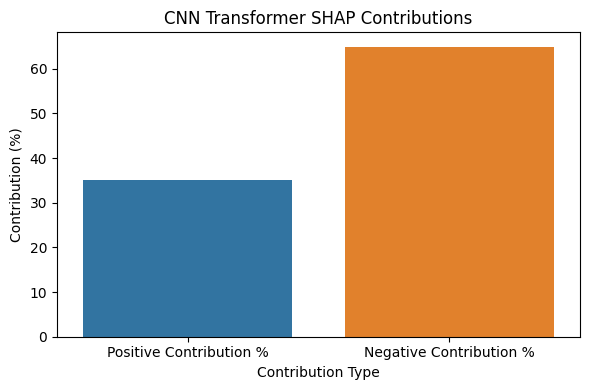

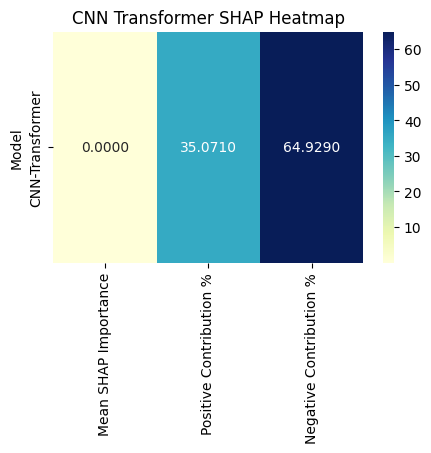


CNN-TRANSFORMER SHAP ANALYSIS COMPLETED


In [24]:
# ============================================================
# SHAP-BASED XAI FEATURE ANALYSIS FOR CNN-TRANSFORMER
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# STORE RESULTS
# ============================================================

shap_results = []

# ============================================================
# TEST SAMPLES
# ============================================================

test_samples = X_test[:10]

print("\n================================================")
print("Running SHAP XAI for CNN-TRANSFORMER")
print("================================================")

try:

    # ========================================================
    # PREDICTION FUNCTION
    # ========================================================

    def predict_fn(images):

        images = np.array(images).astype(np.float32)

        return cnn_transformer.predict(
            images,
            verbose=0
        )

    # ========================================================
    # SHAP MASKER
    # ========================================================

    masker = shap.maskers.Image(
        "blur(32,32)",
        test_samples[0].shape
    )

    # ========================================================
    # SHAP EXPLAINER
    # ========================================================

    explainer = shap.Explainer(
        predict_fn,
        masker
    )

    # ========================================================
    # GENERATE SHAP VALUES
    # ========================================================

    shap_values = explainer(
        test_samples,
        max_evals=200
    )

    print("SHAP values generated successfully.")

    # ========================================================
    # EXTRACT SHAP IMPORTANCE
    # ========================================================

    values = shap_values.values

    values = values[...,0]

    mean_importance = np.mean(
        np.abs(values)
    )

    positive_contribution = np.mean(
        values[values > 0]
    ) if np.any(values > 0) else 0

    negative_contribution = np.mean(
        np.abs(values[values < 0])
    ) if np.any(values < 0) else 0

    total = (
        positive_contribution +
        negative_contribution
    )

    positive_percent = (
        positive_contribution / total
    ) * 100 if total != 0 else 0

    negative_percent = (
        negative_contribution / total
    ) * 100 if total != 0 else 0

    # ========================================================
    # SAVE RESULTS
    # ========================================================

    shap_results.append([
        "CNN-Transformer",
        mean_importance,
        positive_percent,
        negative_percent
    ])

    # ========================================================
    # SHAP HEATMAP
    # ========================================================

    sample_image = test_samples[0]

    shap_map = np.mean(
        np.abs(values[0]),
        axis=2
    )

    plt.figure(figsize=(6,6))

    plt.imshow(sample_image)

    plt.imshow(
        shap_map,
        cmap='jet',
        alpha=0.5
    )

    plt.title(
        "SHAP Heatmap - CNN Transformer"
    )

    plt.axis("off")

    plt.show()

except Exception as e:

    print("Error:", e)

# ============================================================
# RESULTS TABLE
# ============================================================

shap_df = pd.DataFrame(
    shap_results,
    columns=[
        "Model",
        "Mean SHAP Importance",
        "Positive Contribution %",
        "Negative Contribution %"
    ]
)

print("\nSHAP Feature Analysis Table")
print(shap_df)

# ============================================================
# BAR CHART
# ============================================================

shap_melt = shap_df.melt(
    id_vars="Model",
    value_vars=[
        "Positive Contribution %",
        "Negative Contribution %"
    ],
    var_name="Contribution Type",
    value_name="Percentage"
)

plt.figure(figsize=(6,4))

sns.barplot(
    data=shap_melt,
    x="Contribution Type",
    y="Percentage"
)

plt.title(
    "CNN Transformer SHAP Contributions"
)

plt.ylabel("Contribution (%)")

plt.tight_layout()
plt.show()

# ============================================================
# HEATMAP
# ============================================================

plt.figure(figsize=(5,3))

sns.heatmap(
    shap_df.set_index("Model"),
    annot=True,
    cmap="YlGnBu",
    fmt=".4f"
)

plt.title(
    "CNN Transformer SHAP Heatmap"
)

plt.show()

# ============================================================
# COMPLETE
# ============================================================

print("\n================================================")
print("CNN-TRANSFORMER SHAP ANALYSIS COMPLETED")
print("================================================")

PartitionExplainer explainer: 7it [00:13,  6.78s/it]               


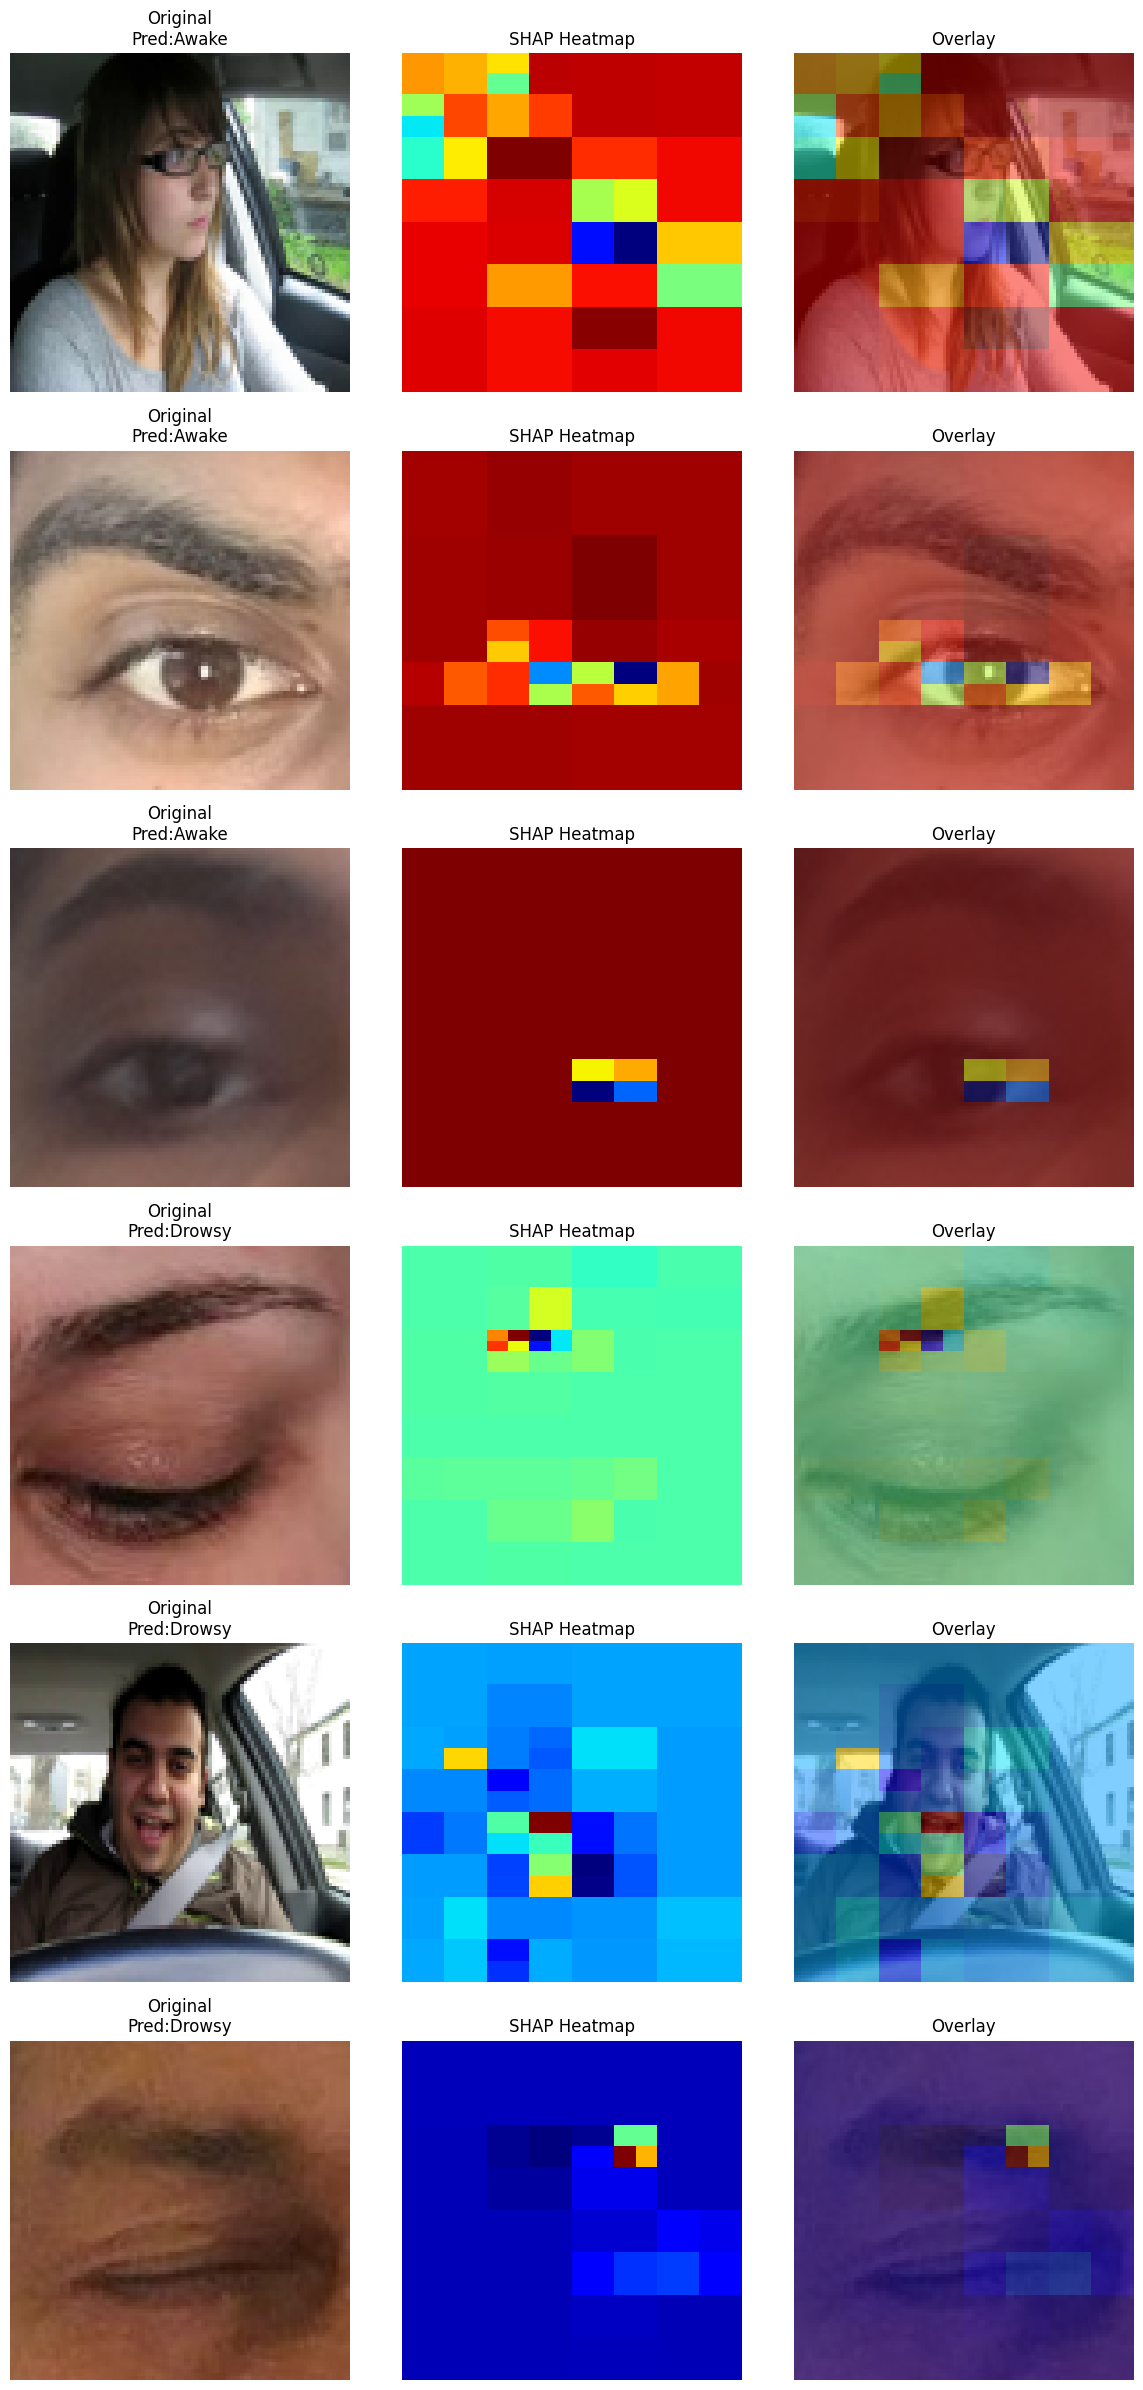

In [25]:
import shap
import numpy as np
import matplotlib.pyplot as plt

# Prediction function
def predict_fn(images):
    images = np.array(images).astype(np.float32)
    return cnn_transformer.predict(images, verbose=0)

def label_text(prob):
    return "Drowsy" if prob > 0.5 else "Awake"

# Pick N examples from each true class (0 = Awake, 1 = Drowsy)
n_per_class = 3
awake_indices = np.where(y_test == 0)[0]
drowsy_indices = np.where(y_test == 1)[0]

sample_indices = list(
    np.random.choice(awake_indices, size=min(n_per_class, len(awake_indices)), replace=False)
) + list(
    np.random.choice(drowsy_indices, size=min(n_per_class, len(drowsy_indices)), replace=False)
)

test_samples = X_test[sample_indices]

# SHAP masker + explainer (built once, shared across samples)
masker = shap.maskers.Image("blur(32,32)", test_samples[0].shape)
explainer = shap.Explainer(predict_fn, masker)

# Generate SHAP values for all selected samples at once
shap_values = explainer(test_samples, max_evals=200)

n = len(sample_indices)
fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))
if n == 1:
    axes = axes.reshape(1, 3)

for row, idx in enumerate(sample_indices):
    image = test_samples[row]
    values = shap_values.values[row][..., 0]          # (H, W, 3) -> per-pixel channel values
    shap_map = np.mean(values, axis=2)                 # collapse channels -> (H, W)

    pred_prob = predict_fn(np.expand_dims(image, axis=0))[0][0]
    pred_label = label_text(pred_prob)

    # --- Column 1: Original + predicted label ---
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original\nPred:{pred_label}")
    axes[row, 0].axis('off')

    # --- Column 2: SHAP Heatmap (pure heatmap, no image underneath) ---
    axes[row, 1].imshow(shap_map, cmap='jet')
    axes[row, 1].set_title("SHAP Heatmap")
    axes[row, 1].axis('off')

    # --- Column 3: Overlay (image + heatmap blended) ---
    axes[row, 2].imshow(image)
    axes[row, 2].imshow(shap_map, cmap='jet', alpha=0.5)
    axes[row, 2].set_title("Overlay")
    axes[row, 2].axis('off')

plt.tight_layout()
plt.show()

In [26]:
# Create folder if not exists
save_dir = "/kaggle/working/model"
os.makedirs(save_dir, exist_ok=True)

# Save model in that folder
model_path = os.path.join(save_dir, "cnn_vit_best.h5")
best_model = cnn_transformer   # CNN-ViT model, used for Explainable AI
best_model.save(model_path)

print(f"CNN-ViT model saved successfully at: {model_path}")

CNN-ViT model saved successfully at: /kaggle/working/model/cnn_vit_best.h5


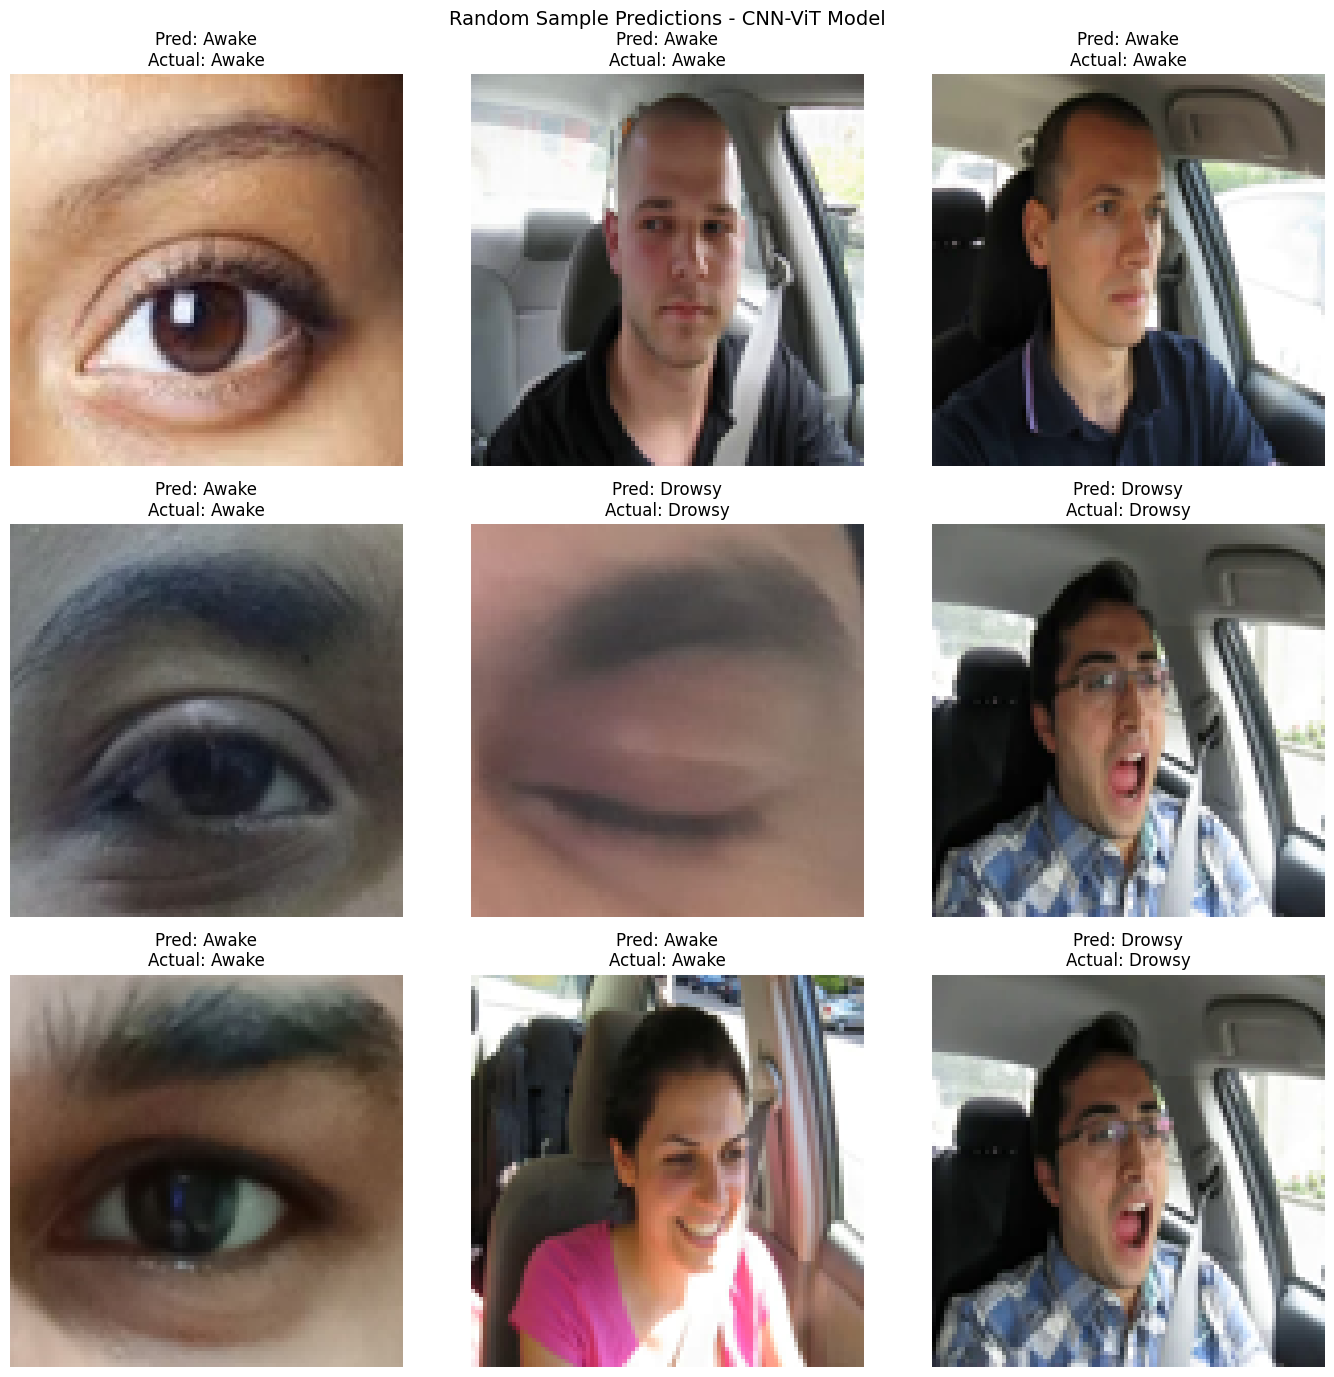

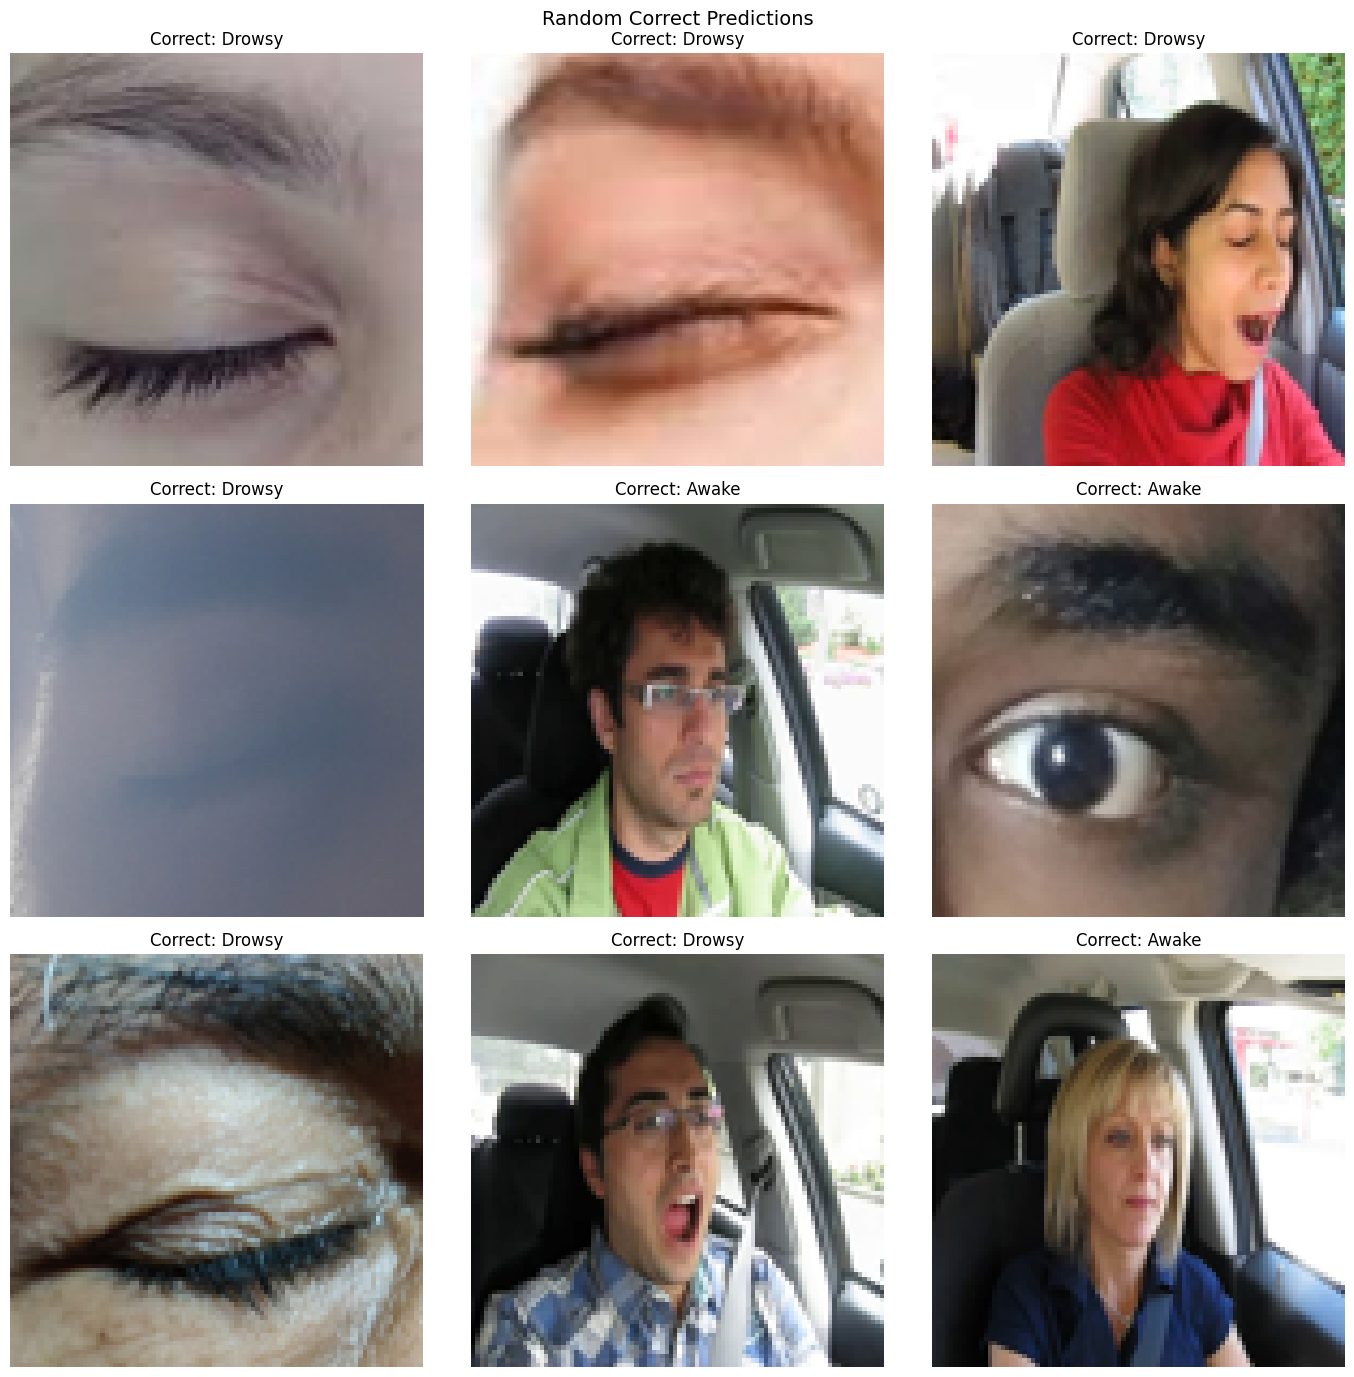

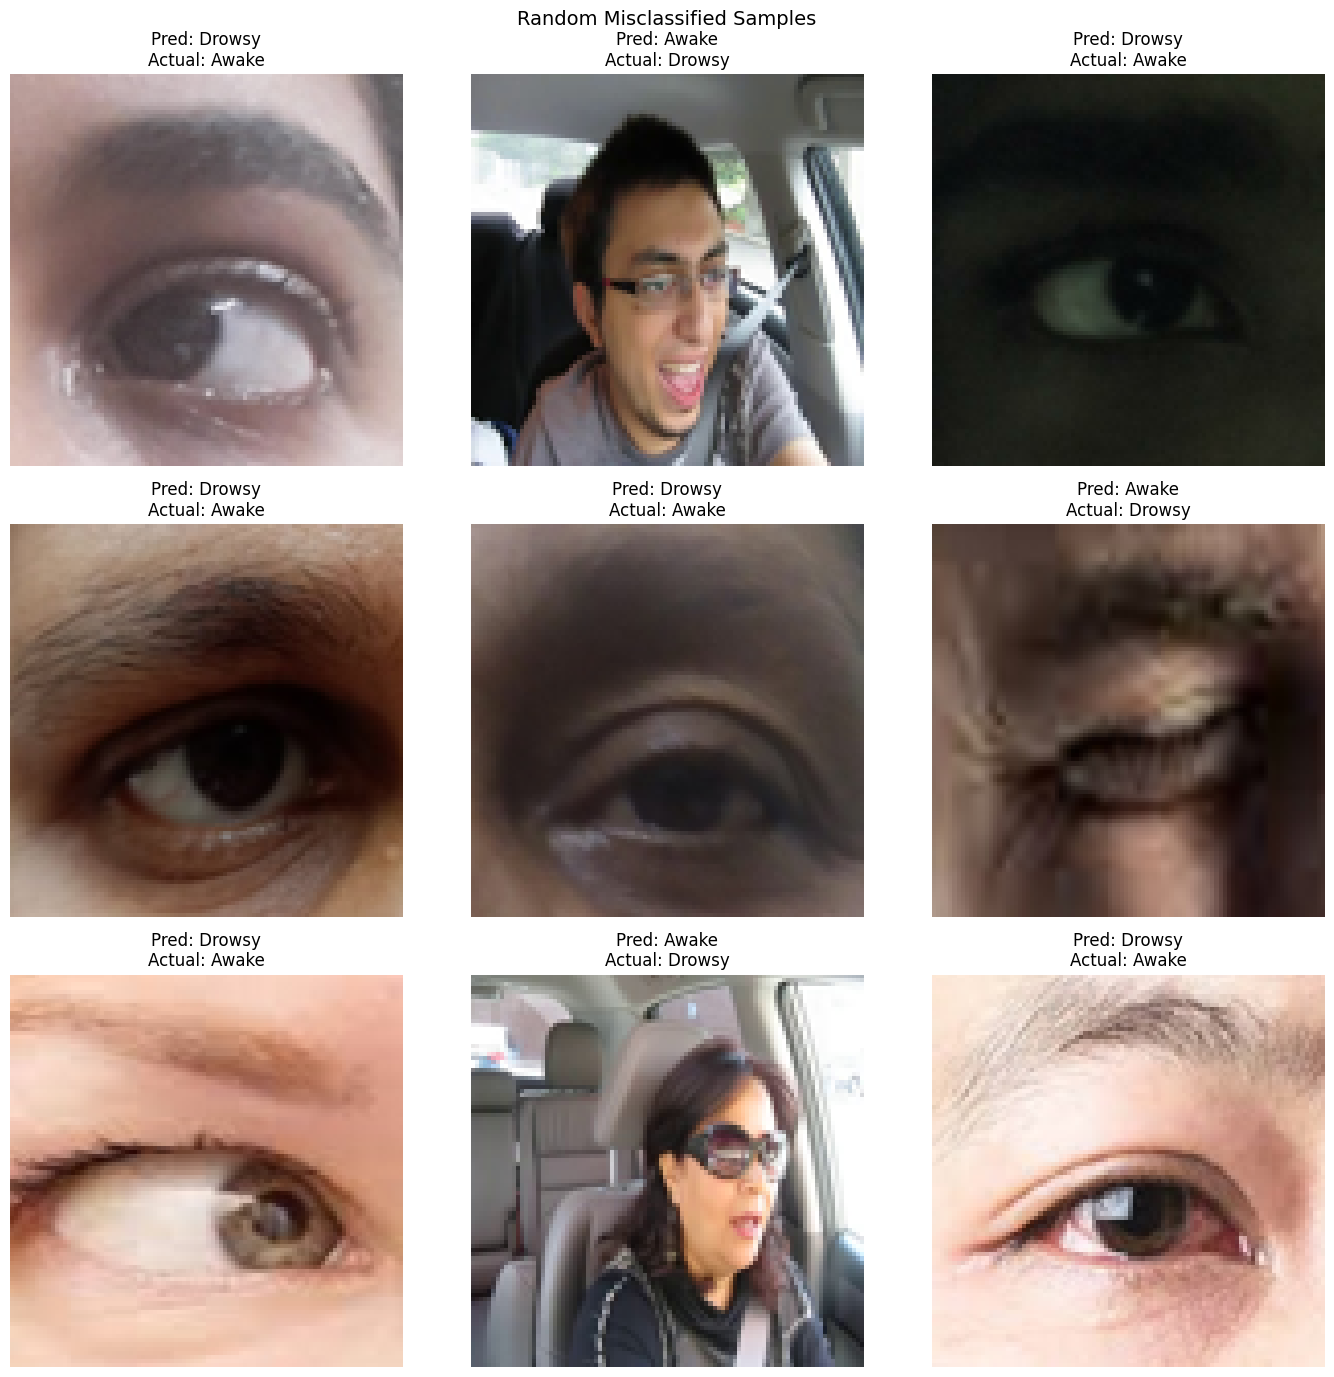

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import random

# Label mapping
def label_text(label):
    return "Drowsy" if label == 1 else "Awake"

# Prediction function
def predict_label(img):
    img_input = np.expand_dims(img, axis=0)
    pred_prob = best_model.predict(img_input, verbose=0)[0][0]
    return 1 if pred_prob > 0.5 else 0

n_samples = 9  # change this for more/fewer per grid
grid_rows, grid_cols = 3, 3

# -------------------------------
# 1. RANDOM SAMPLE PREDICTIONS
# -------------------------------
plt.figure(figsize=(14,14))
plt.suptitle("Random Sample Predictions - CNN-ViT Model", fontsize=14)

indices = random.sample(range(len(X_test)), n_samples)

for i, idx in enumerate(indices):
    img = X_test[idx]
    pred = predict_label(img)
    actual = y_test[idx]

    plt.subplot(grid_rows, grid_cols, i+1)
    plt.imshow(img)
    plt.title(f"Pred: {label_text(pred)}\nActual: {label_text(actual)}")
    plt.axis('off')

plt.tight_layout()
plt.show()


# -------------------------------
# 2. RANDOM CORRECT PREDICTIONS
# -------------------------------
plt.figure(figsize=(14,14))
plt.suptitle("Random Correct Predictions", fontsize=14)

correct_indices = [i for i in range(len(X_test)) if predict_label(X_test[i]) == y_test[i]]
selected = random.sample(correct_indices, min(n_samples, len(correct_indices)))

for i, idx in enumerate(selected):
    plt.subplot(grid_rows, grid_cols, i+1)
    plt.imshow(X_test[idx])
    plt.title(f"Correct: {label_text(y_test[idx])}")
    plt.axis('off')

plt.tight_layout()
plt.show()


# -------------------------------
# 3. RANDOM MISCLASSIFIED SAMPLES
# -------------------------------
plt.figure(figsize=(14,14))
plt.suptitle("Random Misclassified Samples", fontsize=14)

wrong_indices = [i for i in range(len(X_test)) if predict_label(X_test[i]) != y_test[i]]
selected = random.sample(wrong_indices, min(n_samples, len(wrong_indices)))

for i, idx in enumerate(selected):
    pred = predict_label(X_test[idx])
    
    plt.subplot(grid_rows, grid_cols, i+1)
    plt.imshow(X_test[idx])
    plt.title(f"Pred: {label_text(pred)}\nActual: {label_text(y_test[idx])}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [33]:
# ============================================================
# FULL CELL: ablation + XAI fidelity/stability + report text
# Run after cell 14 (X_train 2467, X_test 433 must be loaded)
# ============================================================
import os
import time
import cv2
import shap
import numpy as np
import pandas as pd
import tensorflow as tf
from numpy.linalg import norm
from tensorflow.keras import layers, Model
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

# ---------------- settings ----------------
SEEDS = [0, 1, 2, 3, 4]
EPOCHS = 15
BATCH = 32
N_PER_CLASS = 50
GRID = 12
STEP = 4
SIGMA = 0.01
TRIALS = 50
N_STAB = 20
CELL = 96 // GRID
NCELL = GRID * GRID
CSV = "ablation_all_runs.csv"

try:
    tf.config.experimental.enable_op_determinism()
except Exception as e:
    print("determinism not enabled:", e)

print("X_train", X_train.shape, "X_test", X_test.shape)
assert X_train.shape[0] == 2467, "re-run cell 14"
assert X_test.shape[0] == 433, "re-run cell 14"


# ---------------- model code ----------------
class PosEmb(layers.Layer):
    def build(self, shape):
        self.pe = self.add_weight(
            shape=(1, shape[1], shape[2]),
            initializer="random_normal",
            name="pe")

    def call(self, x):
        return x + self.pe


def cnn_block(x, bn=True):
    for f in (32, 64, 128):
        x = layers.Conv2D(
            f, 3, activation="relu",
            padding="same")(x)
        if bn:
            x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    return x


def transformer_block(x):
    a = layers.MultiHeadAttention(
        num_heads=4, key_dim=32)(x, x)
    x = layers.LayerNormalization(
        epsilon=1e-6)(x + a)
    f = layers.Dense(256, activation="relu")(x)
    f = layers.Dense(128)(f)
    return layers.LayerNormalization(
        epsilon=1e-6)(x + f)


def head(x, dropout):
    x = layers.Dense(128, activation="relu")(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    return layers.Dense(1, activation="sigmoid")(x)


def cfg(front, use_tf, pool, bn, drop):
    return {"front": front, "tf": use_tf,
            "pool": pool, "bn": bn, "drop": drop}


CONFIGS = {}
CONFIGS["cnn_only"] = cfg(
    "cnn", False, "gap", True, 0.3)
CONFIGS["transformer_only"] = cfg(
    "patch", True, "gap", True, 0.3)
CONFIGS["cnn_tf_flatten"] = cfg(
    "cnn", True, "flatten", True, 0.3)
CONFIGS["cnn_tf_gap_no_dropout"] = cfg(
    "cnn", True, "gap", True, 0.0)
CONFIGS["cnn_tf_no_batchnorm"] = cfg(
    "cnn", True, "gap", False, 0.3)
CONFIGS["cnn_tf_full"] = cfg(
    "cnn", True, "gap", True, 0.3)
VARIANTS = list(CONFIGS)


def build(c):
    inp = layers.Input((96, 96, 3))
    if c["front"] == "cnn":
        x = cnn_block(inp, c["bn"])
    else:
        x = layers.Conv2D(
            128, 12, strides=12)(inp)
    if c["tf"]:
        x = layers.Reshape((-1, 128))(x)
        if c["front"] == "patch":
            x = PosEmb()(x)
        x = transformer_block(x)
        if c["pool"] == "flatten":
            x = layers.Flatten()(x)
        else:
            x = layers.GlobalAveragePooling1D()(x)
    else:
        x = layers.GlobalAveragePooling2D()(x)
    out = head(x, c["drop"])
    m = Model(inp, out)
    m.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"])
    return m


def train(variant, seed):
    tf.keras.utils.set_random_seed(seed)
    m = build(CONFIGS[variant])
    m.fit(X_train, y_train,
          epochs=EPOCHS,
          batch_size=BATCH,
          verbose=0)
    return m


chk = build(CONFIGS["cnn_tf_full"])
print("full model params:", chk.count_params())
print("expected: 243265")
assert chk.count_params() == 243265

# ---------------- PART 1: ablation ----------------
if os.path.exists(CSV):
    rows = pd.read_csv(CSV).to_dict("records")
else:
    rows = []
done = set((r["variant"], r["seed"]) for r in rows)
full_model_seed0 = None

for v in VARIANTS:
    for s in SEEDS:
        if (v, s) in done:
            continue
        m = train(v, s)
        prob = m.predict(X_test, verbose=0)
        p = (prob > 0.5).astype(int).ravel()
        tr = sum(int(np.prod(w.shape))
                 for w in m.trainable_weights)
        nt = sum(int(np.prod(w.shape))
                 for w in m.non_trainable_weights)
        row = {}
        row["variant"] = v
        row["seed"] = s
        row["acc"] = accuracy_score(y_test, p) * 100
        row["prec"] = precision_score(
            y_test, p, zero_division=0) * 100
        row["rec"] = recall_score(y_test, p) * 100
        row["f1"] = f1_score(
            y_test, p, zero_division=0) * 100
        row["trainable"] = tr
        row["non_trainable"] = nt
        rows.append(row)
        pd.DataFrame(rows).to_csv(CSV, index=False)
        print(v, s, round(row["acc"], 2))
        if v == "cnn_tf_full" and s == 0:
            full_model_seed0 = m

if full_model_seed0 is None:
    full_model_seed0 = train("cnn_tf_full", 0)

df = pd.DataFrame(rows)
g = df.groupby("variant")
summary = g.agg(
    acc_mean=("acc", "mean"),
    acc_sd=("acc", "std"),
    prec=("prec", "mean"),
    rec=("rec", "mean"),
    f1=("f1", "mean"),
    trainable=("trainable", "first"),
    non_trainable=("non_trainable", "first"))
print(summary.loc[VARIANTS].round(2))

# ---------------- PART 2: XAI ----------------
model = full_model_seed0
trap = getattr(np, "trapezoid", None)
if trap is None:
    trap = np.trapz
rng = np.random.default_rng(42)
sel0 = rng.choice(
    np.where(y_test == 0)[0], N_PER_CLASS,
    replace=False)
sel1 = rng.choice(
    np.where(y_test == 1)[0], N_PER_CLASS,
    replace=False)
idx = np.concatenate([sel0, sel1])


def predict_fn(im):
    im = np.asarray(im, np.float32)
    return model.predict(im, verbose=0)


masker = shap.maskers.Image(
    "blur(32,32)", X_test[0].shape)
explainer = shap.Explainer(predict_fn, masker)


def attribution(imgs):
    sv = explainer(np.asarray(imgs), max_evals=200)
    return sv.values[..., 0].sum(axis=-1)


def cell_scores(a):
    b = a.reshape(GRID, CELL, GRID, CELL)
    return b.sum(axis=(1, 3)).ravel()


def class_prob(p, pred):
    return p if pred == 1 else 1 - p


def del_ins_auc(img, order, pred):
    blur = cv2.blur(img.astype(np.float32), (32, 32))
    ks = list(range(0, NCELL + 1, STEP))
    if ks[-1] != NCELL:
        ks.append(NCELL)
    dels = []
    inss = []
    for k in ks:
        m = np.zeros(NCELL, bool)
        m[order[:k]] = True
        m = m.reshape(GRID, GRID)
        ones = np.ones((CELL, CELL), bool)
        m = np.kron(m, ones)[..., None]
        dels.append(np.where(m, blur, img))
        inss.append(np.where(m, img, blur))
    batch = np.array(dels + inss, np.float32)
    p = model.predict(batch, verbose=0).ravel()
    n = len(ks)
    pd_ = np.array([class_prob(v, pred)
                    for v in p[:n]])
    pi_ = np.array([class_prob(v, pred)
                    for v in p[n:]])
    x = np.array(ks) / NCELL
    return trap(pd_, x), trap(pi_, x)


t0 = time.time()
A = attribution(X_test[idx])
res = []
for j, i in enumerate(idx):
    img = X_test[i]
    p = float(model.predict(img[None], verbose=0)[0, 0])
    pred = int(p > 0.5)
    sign = 1 if pred == 1 else -1
    sc = sign * cell_scores(A[j])
    d, ins = del_ins_auc(img, np.argsort(-sc), pred)
    rd = []
    for _ in range(3):
        o = rng.permutation(NCELL)
        rd.append(del_ins_auc(img, o, pred))
    rd = np.array(rd)
    res.append([d, ins, rd[:, 0].mean(), rd[:, 1].mean()])
res = np.array(res)
print("fidelity done, seconds:", round(time.time() - t0))

t0 = time.time()
stab_idx = list(sel0[:N_STAB // 2])
stab_idx += list(sel1[:N_STAB // 2])
cos_img = []
for n_done, i in enumerate(stab_idx):
    img = X_test[i]
    a0 = attribution(img[None])[0].ravel()
    noisy = []
    for _ in range(TRIALS):
        e = rng.normal(0, SIGMA, img.shape)
        noisy.append(img + e.astype(np.float32))
    an = attribution(np.stack(noisy))
    an = an.reshape(TRIALS, -1)
    den = norm(an, axis=1) * norm(a0) + 1e-12
    cos = (an @ a0) / den
    cos_img.append(cos.mean())
    print("stability image", n_done + 1,
          "of", len(stab_idx))
cos_img = np.array(cos_img)
print("stability done, seconds:", round(time.time() - t0))

# ---------------- PART 3: report text ----------------
LABEL = {
 "cnn_only": "CNN only",
 "transformer_only": "Transformer only",
 "cnn_tf_flatten": "CNN + Transformer (Flatten, no GAP)",
 "cnn_tf_gap_no_dropout": "CNN + Transformer + GAP (no dropout)",
 "cnn_tf_no_batchnorm": "CNN + Transformer + GAP + Dropout (no BatchNorm)",
 "cnn_tf_full": "Proposed model",
}
DIFF = {
 "cnn_only": "Transformer encoder removed",
 "transformer_only": "CNN replaced by 12x12 patch embedding + learned positions",
 "cnn_tf_flatten": "Flatten instead of global average pooling",
 "cnn_tf_gap_no_dropout": "Dropout 0.3 removed",
 "cnn_tf_no_batchnorm": "BatchNorm layers removed",
 "cnn_tf_full": "Reference configuration",
}
m_ = g[["acc", "prec", "rec", "f1"]].mean()
s_ = g["acc"].std()
par = g[["trainable", "non_trainable"]].first()
full_acc = m_.loc["cnn_tf_full", "acc"]

print()
print("=== TABLE 11 ===")
print("Config | Acc mean+/-SD | Prec | Rec | F1 | "
      "Trainable | Non-trainable | Difference")
for v in LABEL:
    row = [
        LABEL[v],
        "%.2f +/- %.2f" % (m_.loc[v, "acc"], s_[v]),
        "%.2f" % m_.loc[v, "prec"],
        "%.2f" % m_.loc[v, "rec"],
        "%.2f" % m_.loc[v, "f1"],
        "{:,}".format(int(par.loc[v, "trainable"])),
        "{:,}".format(int(par.loc[v, "non_trainable"])),
        DIFF[v],
    ]
    print(" | ".join(row))

print()
print("=== SECTION 4.8 ===")
print("Protocol: Adam lr 0.001, batch", BATCH,
      "epochs", EPOCHS, "seeds", SEEDS)
print("train", len(X_train), "test", len(X_test),
      "no validation set, final-epoch weights")
for v in LABEL:
    if v == "cnn_tf_full":
        continue
    d = full_acc - m_.loc[v, "acc"]
    print(LABEL[v], ": %.2f points vs proposed" % d)

print()
print("=== SECTION 4.6.1 ===")
print("Fidelity images:", len(res),
      "(", len(res) // 2, "per class )")
print("Grid", GRID, "x", GRID, "cells of",
      CELL, "x", CELL, "px; step", STEP, "cells")
print("SHAP blur(32,32), max_evals=200; fill=blur(32,32)")
print("target = predicted-class probability")
print("AUC = trapezoid over fraction of cells")
nm = ["Deletion AUC SHAP", "Insertion AUC SHAP",
      "Deletion AUC random", "Insertion AUC random"]
for c in range(4):
    print(nm[c], "%.4f +/- %.4f" % (
        res[:, c].mean(), res[:, c].std(ddof=1)))
print("Stability images:", len(cos_img),
      "trials:", TRIALS, "sigma:", SIGMA)
print("Cosine per-image mean over trials, then mean/SD "
      "across images: %.4f +/- %.4f" % (
          cos_img.mean(), cos_img.std(ddof=1)))

X_train (2467, 96, 96, 3) X_test (433, 96, 96, 3)
full model params: 243265
expected: 243265


2026-11-01 03:10:06.213878: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-11-01 03:10:42.081269: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

cnn_only 0 84.53


2026-11-01 03:11:14.676414: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


cnn_only 1 90.07


2026-11-01 03:11:47.882890: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


... (97 outputs left out)

2026-11-01 04:13:01.752315: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-11-01 04:13:06.808202: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

stability image 19 of 20


2026-11-01 04:15:08.097728: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-11-01 04:15:13.105687: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

stability image 20 of 20
stability done, seconds: 2637

=== TABLE 11 ===
Config | Acc mean+/-SD | Prec | Rec | F1 | Trainable | Non-trainable | Difference
CNN only | 87.53 +/- 7.33 | 92.30 | 81.67 | 86.19 | 110,337 | 448 | Transformer encoder removed
Transformer only | 72.61 +/- 12.51 | 69.98 | 52.65 | 59.88 | 212,737 | 0 | CNN replaced by 12x12 patch embedding + learned positions
CNN + Transformer (Flatten, no GAP) | 95.57 +/- 2.13 | 96.74 | 94.33 | 95.43 | 2,585,729 | 448 | Flatten instead of global average pooling
CNN + Transformer + GAP (no dropout) | 95.52 +/- 2.49 | 95.54 | 95.72 | 95.52 | 242,817 | 448 | Dropout 0.3 removed
CNN + Transformer + GAP + Dropout (no BatchNorm) | 51.59 +/- 3.58 | 39.29 | 43.16 | 31.98 | 242,369 | 0 | BatchNorm layers removed
Proposed model | 87.30 +/- 11.95 | 84.11 | 96.93 | 89.22 | 242,817 | 448 | Reference configuration

=== SECTION 4.8 ===
Protocol: Adam lr 0.001, batch 32 epochs 15 seeds [0, 1, 2, 3, 4]
train 2467 test 433 no validation set, final